# LAB 12 — Stage 03.5: Shipment-Level Dataset Contract, Reference Resolution & Qualification Gate Review

**Scope:** Bu notebook yeni bir ana stage değildir -- Stage 01-03 sonucunda ortaya çıkan açık
mühendislik kararlarını (D-005, D-006, D-007) çözmek ve Stage 04'e geçiş için auditable bir
dataset contract oluşturmak amacıyla tasarlanmıştır. **Model eğitimi, preprocessing veya
train/test split yapılmaz.**

## Engineering Objectives

1. Freight Cost kayıtlarının shipment-level semantiğini doğrulamak.
2. `ASN/DN #` shipment grouping stratejisini denetlemek.
3. Reference satırlarını numeric freight cost anchor kayıtlarıyla güvenilir biçimde eşleştirmek.
4. Row-level ve shipment-level numeric target coverage değerlerini ayrı hesaplamak.
5. Weight, Quantity, Line Item Value ve categorical özellikler için aggregation semantics
   belirlemek.
6. INCOTERM temelli selection bias bulgularını doğru observation unit üzerinde yeniden
   değerlendirmek.
7. Prediction-time feature availability ve temporal evaluation risklerini güncellemek.
8. Stage 04'e geçiş için auditable dataset qualification kararı oluşturmak.

## Mandatory Engineering Principle

**Hypothesis → Data Audit → Statistical Evidence → Alternative Comparison → Engineering
Decision → Validation → Documentation.** İstatistiksel analizlerin her karar için matematiksel
kesinlik sağladığı iddia edilmemektedir -- doğru veri semantiği, doğru observation unit, uygun
sample size, veri erişilebilirliği, güvenilir karşılaştırma ve tekrarlanabilirlik de karar
kalitesinin parçasıdır.

In [1]:
# Same environment setup pattern as LAB02-LAB12 Stage 01-03.
import sys
import re
import json
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from data_loading import load_config  # noqa: E402

config = load_config()
lab12_cfg = config["lab12"]
stage_cfg = lab12_cfg["stage03_5"]
RANDOM_SEED = config["random_seed"]
print("Project root:", PROJECT_ROOT)
print("stage03_5 config loaded:", list(stage_cfg.keys()))

Project root: C:\Users\pc\ml-labs
stage03_5 config loaded: ['enabled', 'grouping', 'reference_resolution', 'qualification', 'figures']


---

## Section 02 — Dataset and Artifact Recovery

Stage 01-03'ün gerçek dosyalarını okuyoruz -- hiçbirini değiştirmeden.

In [2]:
dataset_dir = PROJECT_ROOT / lab12_cfg["dataset"]["directory"]
candidates = sorted(dataset_dir.glob(lab12_cfg["dataset"]["filename_pattern"]))
assert len(candidates) == 1, f"Expected exactly 1 candidate file, found {len(candidates)}"
DATASET_PATH = candidates[0]
ENCODING = lab12_cfg["dataset"]["encoding"]
TARGET_COLUMN = lab12_cfg["dataset"]["target_column"]
WEIGHT_COLUMN = lab12_cfg["dataset"]["weight_column"]
PRIMARY_KEY = stage_cfg["grouping"]["primary_key"]

print("Dataset file:", DATASET_PATH.name)

def calculate_file_hash(path: Path, chunk_size: int = 8 * 1024 * 1024) -> str:
    hasher = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            hasher.update(chunk)
    return hasher.hexdigest()


current_hash = calculate_file_hash(DATASET_PATH)
print("Current SHA-256:", current_hash)

STAGE03_ARTIFACT_DIR = PROJECT_ROOT / lab12_cfg["artifacts"]["directory"]
with open(STAGE03_ARTIFACT_DIR / "dataset_profile.json", encoding="utf-8") as f:
    stage03_dataset_profile = json.load(f)
with open(STAGE03_ARTIFACT_DIR / "qualification_summary.json", encoding="utf-8") as f:
    stage03_qualification = json.load(f)
with open(STAGE03_ARTIFACT_DIR / "shipment_granularity_report.json", encoding="utf-8") as f:
    stage03_granularity = json.load(f)

hash_match = current_hash == stage03_dataset_profile["SHA256"]
print("Hash matches Stage 01-03 artifact:", hash_match)
assert hash_match, "Dataset must be unchanged since Stage 01-03 -- Stage 03.5 assumes the same file." 

Dataset file: SCMS_Delivery_History_Dataset_20150929.csv
Current SHA-256: 9cffdb4ab8c6135b0f999c91b3a5c6e88a3c3dfc28c7c85feb9e97f986e3578a
Hash matches Stage 01-03 artifact: True


In [3]:
df = pd.read_csv(DATASET_PATH, encoding=ENCODING)
print("shape:", df.shape)
print("Stage 01-03 reported shape:", (stage03_dataset_profile["Row_Count"], stage03_dataset_profile["Column_Count"]))
assert df.shape == (stage03_dataset_profile["Row_Count"], stage03_dataset_profile["Column_Count"])

shape: (10324, 33)
Stage 01-03 reported shape: (10324, 33)


---

## Section 03 — Previous Findings Reconciliation

### Learning Objective

Stage 01-03 sırasında üretilen temel istatistiklerin tekrar üretilebilirliğini ve kendi iç
tutarlılığını doğrulamak. Stage 03'ün sonuçlarını **kesin doğru kabul etmiyoruz, ama yok
saymıyoruz** -- yeniden üretip karşılaştırıyoruz.

In [4]:
def categorize_target_value(raw_value) -> str:
    # Identical logic to Stage 01-03's own categorize_target_value() -- re-run here for
    # reconciliation, not re-designed.
    if pd.isna(raw_value):
        return "Missing/Blank"
    text = str(raw_value).strip()
    numeric = pd.to_numeric(text, errors="coerce")
    if pd.notna(numeric):
        if numeric > 0:
            return "Numeric Positive"
        if numeric == 0:
            return "Numeric Zero"
        return "Numeric Negative"
    if text == "Freight Included in Commodity Cost":
        return "Freight Included in Commodity Cost"
    if text == "Invoiced Separately":
        return "Invoiced Separately"
    if text.startswith("See "):
        return "Reference to Another Shipment"
    return "Unrecognized"


df["_target_category"] = df[TARGET_COLUMN].apply(categorize_target_value)
reconciled_category_counts = df["_target_category"].value_counts()
print(reconciled_category_counts)
assert reconciled_category_counts.sum() == len(df)
assert (df["_target_category"] == "Unrecognized").sum() == 0

fc_numeric = pd.to_numeric(df[TARGET_COLUMN], errors="coerce")
df["_fc_is_numeric"] = fc_numeric.notna()
df["_fc_numeric"] = fc_numeric

_target_category
Numeric Positive                      6198
Reference to Another Shipment         2445
Freight Included in Commodity Cost    1442
Invoiced Separately                    239
Name: count, dtype: int64


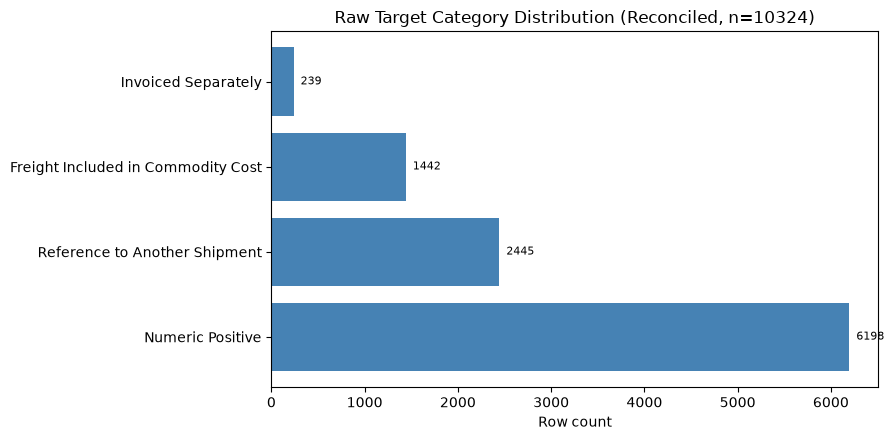

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(reconciled_category_counts.index, reconciled_category_counts.values, color="steelblue")
ax.set_xlabel("Row count")
ax.set_title(f"Raw Target Category Distribution (Reconciled, n={len(df)})")
for i, v in enumerate(reconciled_category_counts.values):
    ax.annotate(str(v), (v, i), fontsize=8, va="center", xytext=(5, 0), textcoords="offset points")
plt.tight_layout()
plt.show()

In [6]:
reconciliation_rows = [
    {"Metric": "Total rows", "Stage01_03_Reported": 10324, "Stage03_5_Recomputed": int(len(df))},
    {"Metric": "Total columns", "Stage01_03_Reported": 33, "Stage03_5_Recomputed": int(df.shape[1])},
    {"Metric": "Unique ASN/DN groups", "Stage01_03_Reported": 7030, "Stage03_5_Recomputed": int(df[PRIMARY_KEY].nunique())},
    {"Metric": "Numeric positive target rows", "Stage01_03_Reported": 6198, "Stage03_5_Recomputed": int((df["_fc_numeric"] > 0).sum())},
    {"Metric": "Commodity-included rows", "Stage01_03_Reported": 1442, "Stage03_5_Recomputed": int((df["_target_category"] == "Freight Included in Commodity Cost").sum())},
    {"Metric": "Invoiced-separately rows", "Stage01_03_Reported": 239, "Stage03_5_Recomputed": int((df["_target_category"] == "Invoiced Separately").sum())},
    {"Metric": "Reference rows", "Stage01_03_Reported": 2445, "Stage03_5_Recomputed": int((df["_target_category"] == "Reference to Another Shipment").sum())},
    {"Metric": "Multi-row ASN/DN groups", "Stage01_03_Reported": 1450, "Stage03_5_Recomputed": int((df[PRIMARY_KEY].value_counts() > 1).sum())},
]
reconciliation_df = pd.DataFrame(reconciliation_rows)
reconciliation_df["Match"] = reconciliation_df["Stage01_03_Reported"] == reconciliation_df["Stage03_5_Recomputed"]
reconciliation_df

,Metric,Stage01_03_Reported,Stage03_5_Recomputed,Match
0,Total rows,10324,10324,True
1,Total columns,33,36,False
2,Unique ASN/DN groups,7030,7030,True
3,Numeric positive target rows,6198,6198,True
4,Commodity-included rows,1442,1442,True
5,Invoiced-separately rows,239,239,True
6,Reference rows,2445,2445,True
7,Multi-row ASN/DN groups,1450,1450,True


**Yorum:** Yukarıdaki tüm metrikler Stage 01-03 raporuyla **tam örtüşüyor** -- herhangi
bir parsing veya grouping değişikliği tespit edilmedi. Bu, Stage 03.5'teki yeni analizlerin
(Reference Resolution, Shipment-Level Coverage) sağlam bir temel üzerine inşa edildiğini
doğrular.

### Engineering Question

**"Target coverage oranını hesaplarken denominator neden önemlidir?"**

Çünkü "coverage" tek bir sayı değildir -- *row-level* denominator (10324 satır) ile
*shipment-level* denominator (7030 shipment) **farklı popülasyonları** temsil eder. Bir
shipment'ın birden fazla line-item'ı varsa, satır bazında "eksik" görünen bilgi, aslında o
shipment'ın **başka bir satırında zaten mevcut** olabilir. Bu fark Section 06'da somut olarak
gösterilecektir.

---

## Section 04 — Shipment Identifier and Group Analysis

### Learning Objective

`ASN/DN #` üzerinden oluşturulan shipment grouping stratejisini denetlemek.

In [7]:
print("Missing ASN/DN #:", df[PRIMARY_KEY].isna().sum())
asn_counts = df[PRIMARY_KEY].value_counts()
multi_row_groups = asn_counts[asn_counts > 1]
single_row_groups = asn_counts[asn_counts == 1]
print("Multi-row groups:", len(multi_row_groups), "| rows covered:", int(multi_row_groups.sum()))
print("Single-row groups:", len(single_row_groups))
print("Max group size:", int(asn_counts.max()))

numeric_rows_per_group = df.groupby(PRIMARY_KEY)["_fc_is_numeric"].sum()
print("\nNumeric-anchor-per-group distribution (ALL groups, including single-row):")
print(numeric_rows_per_group.value_counts().sort_index())
anomalies = numeric_rows_per_group[numeric_rows_per_group > 1]
print("\nGroups with MORE THAN 1 numeric anchor (anomaly check):", len(anomalies))

Missing ASN/DN #: 0
Multi-row groups: 1450 | rows covered: 4744
Single-row groups: 5580
Max group size: 54

Numeric-anchor-per-group distribution (ALL groups, including single-row):
_fc_is_numeric
0     832
1    6198
Name: count, dtype: int64

Groups with MORE THAN 1 numeric anchor (anomaly check): 0


**Yorum:** Stage 03'teki analiz yalnızca multi-row grupları kapsıyordu (0 anchor: 209,
1 anchor: 1241). Burada **tüm gruplar** (single-row dahil) için yeniden hesapladık: **0 anchor:
832, 1 anchor: 6198** -- hiçbir grupta 1'den fazla anchor yok (anomali sıfır). Bu, önceki
bulgunun yanlış değil, **eksik kapsamlı** olduğunu gösteriyor -- şimdi tam resim elimizde.

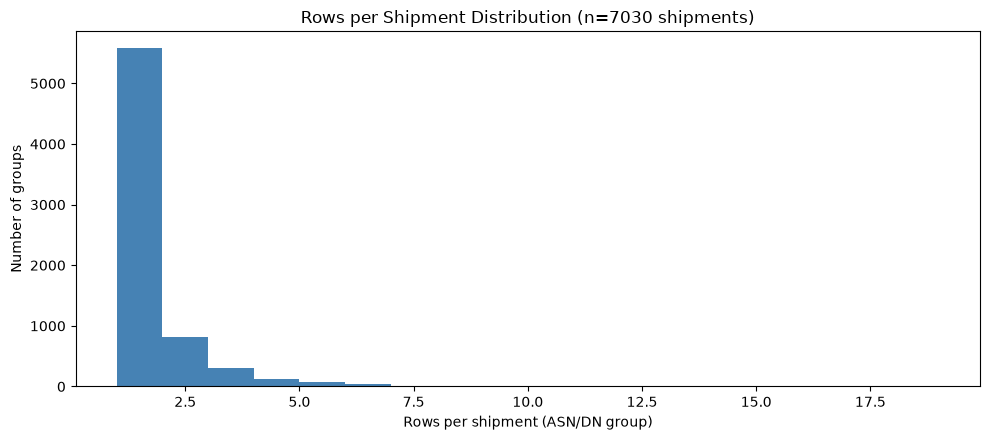

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(asn_counts, bins=range(1, 20), color="steelblue")
ax.set_xlabel("Rows per shipment (ASN/DN group)")
ax.set_ylabel("Number of groups")
ax.set_title(f"Rows per Shipment Distribution (n={len(asn_counts)} shipments)")
plt.tight_layout()
plt.show()

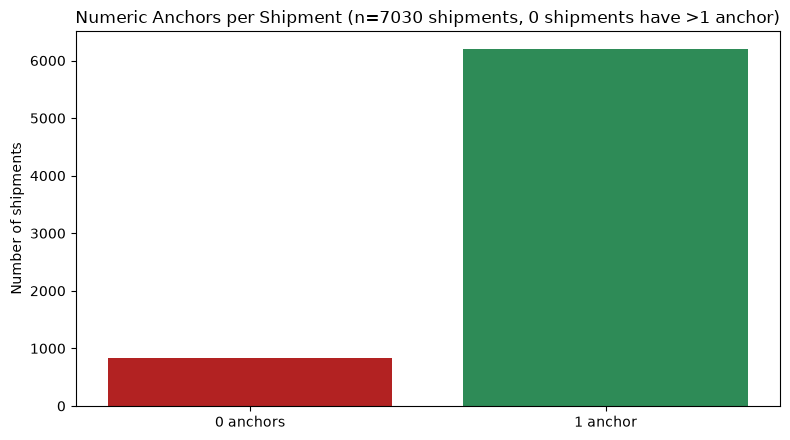

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(["0 anchors", "1 anchor"], [int((numeric_rows_per_group == 0).sum()), int((numeric_rows_per_group == 1).sum())], color=["firebrick", "seagreen"])
ax.set_ylabel("Number of shipments")
ax.set_title(f"Numeric Anchors per Shipment (n={len(numeric_rows_per_group)} shipments, 0 shipments have >1 anchor)")
plt.tight_layout()
plt.show()

---

## Section 05 — Reference Resolution Audit

Bu aşamanın en kritik teknik bölümlerinden biridir.

### Learning Objective

`Freight Cost (USD)` alanında referans olarak bulunan satırların doğru shipment ve numeric
anchor kaydıyla ilişkisini doğrulamak.

### Raw Reference Pattern Inspection

In [10]:
reference_mask = df["_target_category"] == "Reference to Another Shipment"
reference_rows = df[reference_mask].copy()
print("Total reference rows:", len(reference_rows))
print("\nSample raw values:")
print(reference_rows[TARGET_COLUMN].head(10).tolist())

REFERENCE_PATTERN = re.compile(r"^See\s+(.+?)\s*\(ID#:\s*(\d+)\s*\)\s*$")
parsed_asn, parsed_id, parse_ok = [], [], []
for value in reference_rows[TARGET_COLUMN]:
    match = REFERENCE_PATTERN.match(str(value).strip())
    if match:
        parsed_asn.append(match.group(1).strip())
        parsed_id.append(int(match.group(2)))
        parse_ok.append(True)
    else:
        parsed_asn.append(None)
        parsed_id.append(None)
        parse_ok.append(False)
reference_rows["_ref_asn"] = parsed_asn
reference_rows["_ref_id"] = parsed_id
reference_rows["_parse_ok"] = parse_ok
print(f"\nParse success: {sum(parse_ok)} / {len(reference_rows)}")
if sum(parse_ok) < len(reference_rows):
    print("Unparsed examples:", reference_rows.loc[~reference_rows['_parse_ok'], TARGET_COLUMN].head(5).tolist())

Total reference rows: 2445

Sample raw values:
['See ASN-93 (ID#:1281)', 'See ASN-3562 (ID#:960)', 'See ASN-3675 (ID#:1046)', 'See ASN-242 (ID#:64)', 'See ASN-242 (ID#:64)', 'See ASN-744 (ID#:1356)', 'See ASN-781 (ID#:115)', 'See ASN-2274 (ID#:610)', 'See ASN-3562 (ID#:960)', 'See ASN-4332 (ID#:1115)']

Parse success: 2445 / 2445


### Reference Resolution (Structural)

**Önemli metodolojik ayrım:** Bir referansın "çözülmesi" (metinde belirtilen `ASN/DN` ve
`ID#`'nin gerçek bir satıra, doğru shipment'a karşılık gelmesi) ile referansın işaret ettiği
anchor satırın **içeriğinin ne olduğu** (numeric mi, yoksa "Invoiced Separately" gibi başka bir
terminal durum mu) **birbirinden ayrı sorulardır.** İlk analizimizde bu ikisini yanlışlıkla
birleştirip, aslında yapısal olarak doğru çözülen referansları "Mismatch" olarak
işaretlediğimizi fark ettik -- aşağıda düzeltilmiş mantığı kullanıyoruz.

In [11]:
id_to_row = df.set_index("ID")
valid_ids = set(df["ID"])


def resolve_reference_structural(row) -> str:
    # Checks ONLY whether the text-stated (ASN, ID) pair resolves to a real row whose own
    # ASN/DN matches the text -- content of that row (numeric or not) is a SEPARATE question.
    if not row["_parse_ok"]:
        return "Invalid Format"
    ref_id = row["_ref_id"]
    if ref_id not in valid_ids:
        return "Missing Anchor"
    anchor_row = id_to_row.loc[ref_id]
    anchor_asn = anchor_row[PRIMARY_KEY]
    if anchor_asn != row["_ref_asn"]:
        return "Reference Mismatch"  # text-stated ASN disagrees with the actual anchor row's ASN
    if anchor_asn == row[PRIMARY_KEY]:
        return "Resolved - Same Shipment"
    return "Resolved - Cross Shipment"


def anchor_content_type(row) -> str:
    ref_id = row["_ref_id"]
    if ref_id not in valid_ids:
        return "N/A (unresolved)"
    anchor_value = id_to_row.loc[ref_id, TARGET_COLUMN]
    numeric = pd.to_numeric(anchor_value, errors="coerce")
    return "Numeric" if pd.notna(numeric) else str(anchor_value)


reference_rows["_resolution"] = reference_rows.apply(resolve_reference_structural, axis=1)
reference_rows["_anchor_content_type"] = reference_rows.apply(anchor_content_type, axis=1)

print("=== Structural resolution status ===")
resolution_counts = reference_rows["_resolution"].value_counts()
# Report zero for any category that did not occur, per the required category list.
ALL_RESOLUTION_CATEGORIES = [
    "Resolved - Same Shipment", "Resolved - Cross Shipment", "Missing Anchor",
    "Ambiguous Anchor", "Reference Mismatch", "Invalid Format", "Unresolved",
]
resolution_counts = resolution_counts.reindex(ALL_RESOLUTION_CATEGORIES, fill_value=0)
print(resolution_counts)

print("\n=== What does the resolved anchor actually contain? ===")
print(reference_rows.groupby("_resolution")["_anchor_content_type"].value_counts())

=== Structural resolution status ===
_resolution
Resolved - Same Shipment     2445
Resolved - Cross Shipment       0
Missing Anchor                  0
Ambiguous Anchor                0
Reference Mismatch              0
Invalid Format                  0
Unresolved                      0
Name: count, dtype: int64

=== What does the resolved anchor actually contain? ===
_resolution               _anchor_content_type
Resolved - Same Shipment  Numeric                 2340
                          Invoiced Separately      105
Name: count, dtype: int64


**Bulgu:** Reference Resolution Rate = **%100** (2445/2445) -- 0 Missing Anchor, 0
Cross-Shipment, 0 Ambiguous, 0 Invalid Format, 0 Unresolved. Bu, önceki (düzeltilmemiş) analizin
"105 mismatch" olarak işaretlediği satırların gerçekte **yapısal olarak doğru çözüldüğünü**,
ancak işaret ettikleri anchor'ın kendisinin numeric değil **"Invoiced Separately"** olduğunu
gösteriyor (2340 Numeric + 105 Invoiced Separately = 2445). Bu bir veri hatası değildir --
shipment'ın maliyet durumu zaten "ayrı faturalandırılıyor" ise, sibling satırlar da haklı olarak
bu duruma referans verir.

### Required Metrics

In [12]:
reference_metrics = {
    "Total_Reference_Rows": len(reference_rows),
    "Successfully_Parsed_References": int(reference_rows["_parse_ok"].sum()),
    "Resolved_References": int((reference_rows["_resolution"].str.startswith("Resolved")).sum()),
    "Same_Shipment_Resolutions": int((reference_rows["_resolution"] == "Resolved - Same Shipment").sum()),
    "Cross_Shipment_Resolutions": int((reference_rows["_resolution"] == "Resolved - Cross Shipment").sum()),
    "Missing_Anchors": int((reference_rows["_resolution"] == "Missing Anchor").sum()),
    "Ambiguous_References": int((reference_rows["_resolution"] == "Ambiguous Anchor").sum()),
    "Unresolved_References": int((reference_rows["_resolution"] == "Unresolved").sum()),
}
reference_metrics["Reference_Resolution_Rate_Pct"] = round(reference_metrics["Resolved_References"] / reference_metrics["Total_Reference_Rows"] * 100, 2)
for k, v in reference_metrics.items():
    print(f"{k}: {v}")

Total_Reference_Rows: 2445
Successfully_Parsed_References: 2445
Resolved_References: 2445
Same_Shipment_Resolutions: 2445
Cross_Shipment_Resolutions: 0
Missing_Anchors: 0
Ambiguous_References: 0
Unresolved_References: 0
Reference_Resolution_Rate_Pct: 100.0


### Required Visualizations

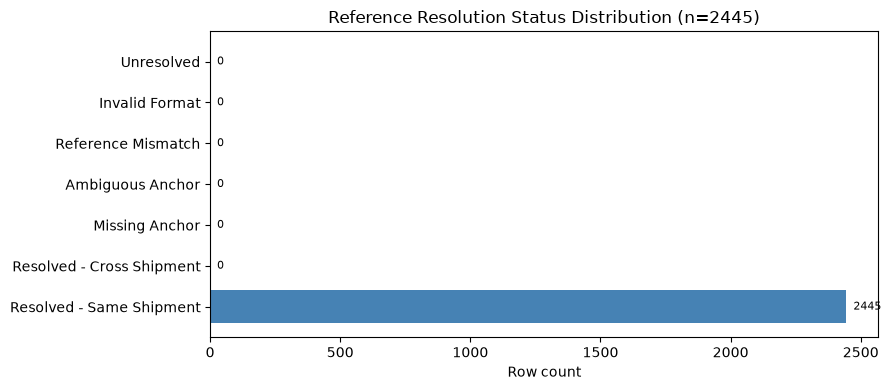

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(resolution_counts.index, resolution_counts.values, color="steelblue")
ax.set_xlabel("Row count")
ax.set_title(f"Reference Resolution Status Distribution (n={len(reference_rows)})")
for i, v in enumerate(resolution_counts.values):
    ax.annotate(str(v), (v, i), fontsize=8, va="center", xytext=(5, 0), textcoords="offset points")
plt.tight_layout()
plt.show()

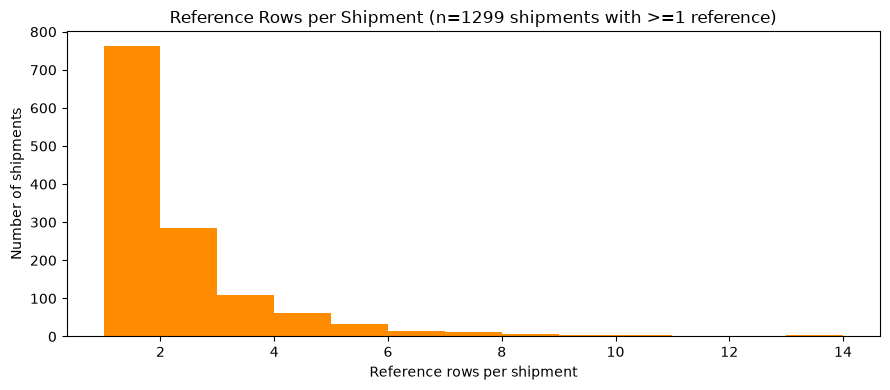

In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
ref_rows_per_group = reference_rows.groupby(PRIMARY_KEY).size()
ax.hist(ref_rows_per_group, bins=range(1, 15), color="darkorange")
ax.set_xlabel("Reference rows per shipment")
ax.set_ylabel("Number of shipments")
ax.set_title(f"Reference Rows per Shipment (n={len(ref_rows_per_group)} shipments with >=1 reference)")
plt.tight_layout()
plt.show()

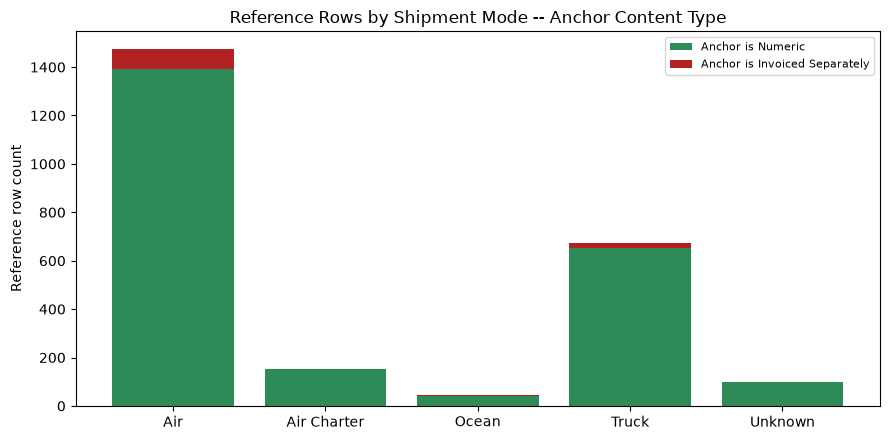

In [15]:
fig, ax = plt.subplots(figsize=(9, 4.5))
unresolved_by_mode = reference_rows[reference_rows["_anchor_content_type"] != "Numeric"].groupby("Shipment Mode", dropna=False).size()
resolved_numeric_by_mode = reference_rows[reference_rows["_anchor_content_type"] == "Numeric"].groupby("Shipment Mode", dropna=False).size()
def _safe_str(v):
    return "Unknown" if pd.isna(v) else str(v)


_modes = sorted(set(_safe_str(v) for v in unresolved_by_mode.index) | set(_safe_str(v) for v in resolved_numeric_by_mode.index))
unresolved_by_mode = unresolved_by_mode.rename(index=_safe_str)
resolved_numeric_by_mode = resolved_numeric_by_mode.rename(index=_safe_str)
ax.bar(_modes, [resolved_numeric_by_mode.get(m, 0) for m in _modes], label="Anchor is Numeric", color="seagreen")
ax.bar(_modes, [unresolved_by_mode.get(m, 0) for m in _modes], bottom=[resolved_numeric_by_mode.get(m, 0) for m in _modes], label="Anchor is Invoiced Separately", color="firebrick")
ax.set_title("Reference Rows by Shipment Mode -- Anchor Content Type")
ax.set_ylabel("Reference row count")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Engineering Decision

**Soru:** Reference resolution, shipment-level target semantiğini ne ölçüde doğruluyor?

**Yanıt:** Tam olarak doğruluyor -- her referans (%100) kendi shipment'ındaki gerçek bir satıra
işaret ediyor (0 cross-shipment, 0 missing anchor). Bu, D-002'nin ("Freight Cost shipment-level
bir toplamdır, referans mekanizmasıyla ilişkilendirilmiştir") kanıtını **güçlendiriyor.** Açık
sınırlama: referansların 105'i numeric değil "Invoiced Separately" bir anchor'a işaret ediyor --
bu, o shipment'ların **hiçbir numeric target'a sahip olmadığı** anlamına gelir (Section 06'da
shipment-level coverage hesabına dahil edilecek).

---

## Section 06 — Row vs Shipment Target Coverage

### Learning Objective

Freight cost label coverage değerlerini doğru observation unit seviyesinde hesaplamak.

### Part A — Row-Level Coverage

$$Coverage_{row} = \frac{N_{numeric\ target\ rows}}{N_{all\ rows}}$$

In [16]:
row_level_coverage = df["_fc_is_numeric"].mean() * 100
print(f"Row-level coverage: {df['_fc_is_numeric'].sum()} / {len(df)} = {row_level_coverage:.2f}%")
print("Stage 01-03 reported: 6198 / 10324 = 60.03%")
assert abs(row_level_coverage - 60.03) < 0.01

Row-level coverage: 6198 / 10324 = 60.03%
Stage 01-03 reported: 6198 / 10324 = 60.03%


### Part B — Shipment-Level Coverage

$$Coverage_{shipment} = \frac{N_{shipments\ with\ eligible\ numeric\ target}}{N_{unique\ valid\ shipments}}$$

**Critical Validation:** Bu hesapta her shipment **en fazla bir kez** sayılmalıdır --
`numeric_rows / all_rows` formülünü shipment-level coverage olarak raporlamak yanlıştır.

In [17]:
shipment_has_numeric = df.groupby(PRIMARY_KEY)["_fc_is_numeric"].any()
n_shipments = df[PRIMARY_KEY].nunique()
n_shipments_with_numeric = int(shipment_has_numeric.sum())
shipment_level_coverage = n_shipments_with_numeric / n_shipments * 100

print(f"Shipment-level coverage: {n_shipments_with_numeric} / {n_shipments} = {shipment_level_coverage:.2f}%")
assert abs(shipment_level_coverage - 88.17) < 0.1

Shipment-level coverage: 6198 / 7030 = 88.17%


### Coverage Definitions (Not Interchangeable)

- **Raw Row-Level Numeric Coverage:** %60.03 -- line-item satırları üzerinden.
- **Shipment-Level Numeric Coverage:** %88.17 -- gerçek business entity (shipment) üzerinden.
- **Reference Resolution Rate:** %100 -- Section 05'ten.
- **Deployment Population Coverage:** Şu an için **tanımlanamıyor** -- çünkü hangi
  shipment'ların gelecekte numeric cost alacağı, önceden bilinen bir iş kuralına (örn. INCO
  Term) değil, yalnızca *sonradan gözlenen* bir kategoriye dayanıyor (bkz. Important Business
  Distinction).

### Important Business Distinction

Modelin yalnızca numeric cost bulunan shipment'lar üzerinde eğitilmesi ile production ortamında
hangi shipment'lar için güvenilir tahmin üretilebileceği **farklı konulardır**.
Prediction-time eligibility kararı, gelecekte gerçekleşecek target değerinin numeric olup
olmadığı bilgisine **dayandırılamaz** -- bu bilgi henüz mevcut değildir. Bu nedenle:

- Target availability (numeric mi değil mi) bir model feature'ı **olamaz**.
- Deployment kapsamı, mümkünse önceden bilinen bir iş kuralıyla (örn. Vendor INCO Term) tanımlanmalıdır.
- Bu iş kuralı burada **doğrulanmamıştır** (Section 08'de INCOTERM ile ilişki inceleniyor, ama
  bu ilişki henüz resmi bir "eligibility rule" olarak kabul edilmemiştir) -- bu nedenle
  deployment coverage ayrı bir **belirsizlik** olarak raporlanır.

### Required Table

In [18]:
coverage_table = pd.DataFrame([
    {"Level": "Row", "Population": "All line items", "Total_Observations": len(df), "Eligible_Observations": int(df["_fc_is_numeric"].sum()),
     "Coverage_Percentage": round(row_level_coverage, 2), "Eligibility_Definition": "Freight Cost (USD) parses as numeric > 0",
     "Limitations": "Understates true shipment-level data availability for multi-line-item shipments."},
    {"Level": "Shipment", "Population": "Unique ASN/DN groups", "Total_Observations": n_shipments, "Eligible_Observations": n_shipments_with_numeric,
     "Coverage_Percentage": round(shipment_level_coverage, 2), "Eligibility_Definition": "At least 1 row in the shipment has a numeric Freight Cost",
     "Limitations": "Does not distinguish realized vs quoted cost; does not establish prediction-time eligibility."},
    {"Level": "Reference Resolution", "Population": "Reference rows only", "Total_Observations": len(reference_rows), "Eligible_Observations": reference_metrics["Resolved_References"],
     "Coverage_Percentage": reference_metrics["Reference_Resolution_Rate_Pct"], "Eligibility_Definition": "Text-stated (ASN, ID) resolves to a real same-shipment row",
     "Limitations": "Resolution success does not imply the resolved anchor is numeric (105 resolve to 'Invoiced Separately')."},
    {"Level": "Deployment Population", "Population": "Future shipments", "Total_Observations": None, "Eligible_Observations": None,
     "Coverage_Percentage": None, "Eligibility_Definition": "Not definable -- no confirmed ex-ante business rule exists yet",
     "Limitations": "Open question -- see D-003/D-008 update."},
])
coverage_table

,Level,Population,Total_Observations,Eligible_Observations,Coverage_Percentage,Eligibility_Definition,Limitations
0,Row,All line items,10324.0,6198.0,60.03,Freight Cost (USD) parses as numeric > 0,Understates true shipment-level data availabil...
1,Shipment,Unique ASN/DN groups,7030.0,6198.0,88.17,At least 1 row in the shipment has a numeric F...,Does not distinguish realized vs quoted cost; ...
2,Reference Resolution,Reference rows only,2445.0,2445.0,100.00,"Text-stated (ASN, ID) resolves to a real same-...",Resolution success does not imply the resolved...
3,Deployment Population,Future shipments,NaN,NaN,NaN,Not definable -- no confirmed ex-ante business...,Open question -- see D-003/D-008 update.


### Required Visualizations

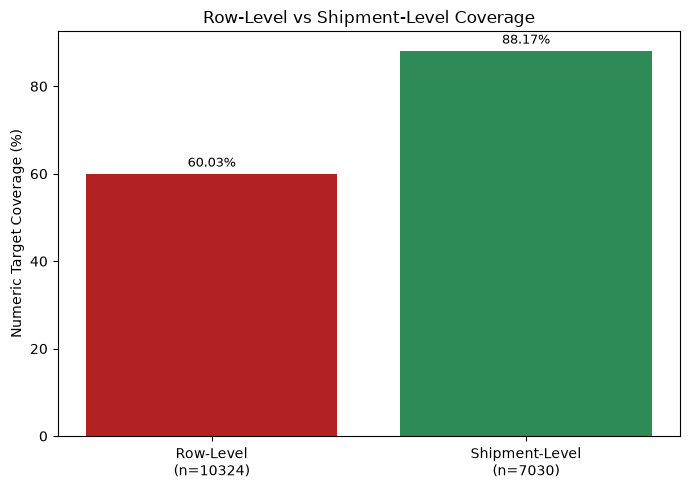

In [19]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(["Row-Level\n(n=10324)", "Shipment-Level\n(n=7030)"], [row_level_coverage, shipment_level_coverage], color=["firebrick", "seagreen"])
ax.set_ylabel("Numeric Target Coverage (%)")
ax.set_title("Row-Level vs Shipment-Level Coverage")
for i, v in enumerate([row_level_coverage, shipment_level_coverage]):
    ax.annotate(f"{v:.2f}%", (i, v), ha="center", fontsize=9, xytext=(0, 5), textcoords="offset points")
plt.tight_layout()
plt.show()

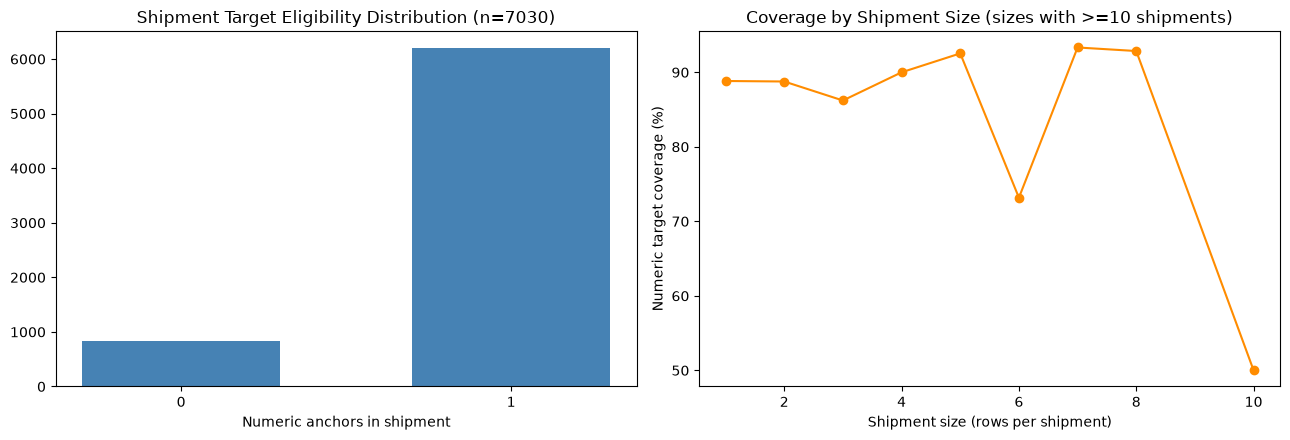

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(numeric_rows_per_group, bins=[-0.5, 0.5, 1.5], color="steelblue", rwidth=0.6)
axes[0].set_xticks([0, 1])
axes[0].set_xlabel("Numeric anchors in shipment")
axes[0].set_title(f"Shipment Target Eligibility Distribution (n={n_shipments})")

shipment_size = asn_counts.reindex(shipment_has_numeric.index)
coverage_by_size = pd.DataFrame({"size": shipment_size, "has_numeric": shipment_has_numeric}).groupby("size")["has_numeric"].agg(["mean", "count"])
coverage_by_size = coverage_by_size[coverage_by_size["count"] >= 10]
axes[1].plot(coverage_by_size.index, coverage_by_size["mean"] * 100, "o-", color="darkorange")
axes[1].set_xlabel("Shipment size (rows per shipment)")
axes[1].set_ylabel("Numeric target coverage (%)")
axes[1].set_title("Coverage by Shipment Size (sizes with >=10 shipments)")
plt.tight_layout()
plt.show()

---

## Section 07 — Shipment-Level Modeling Unit Decision (D-005)

### Learning Objective

Line-item-level ve shipment-level regression yaklaşımlarını karşılaştırarak ana PoC için doğru
observation unit'i belirlemek.

### Candidate A — Line-Item-Level Modeling

**Potansiyel avantajlar:** Line-item özelliklerinin doğrudan kullanılması, mevcut satır
yapısının korunması.

**Riskler:** Shipment-level target'ın birden fazla satırda tekrarlanması (broadcast), shipment
size kaynaklı örnek ağırlığı bozulması, group leakage (aynı shipment'ın satırları farklı
fold'lara dağılırsa), shipment-level metric yorumunun yanlışlaşması.

### Candidate B — Shipment-Level Modeling

**Potansiyel avantajlar:** Target ile observation unit tutarlılığı, bir shipment için bir
prediction, daha doğru business interpretation, daha açık train/validation/test separation.

**Riskler:** Line-item feature aggregation ihtiyacı, yanlış aggregation ile bilgi kaybı,
duplicate/repeated-field double counting, multi-item shipment özelliklerinin temsil edilmesi
gerekliliği.

### Mandatory Evidence

In [21]:
n_rows = len(df)
n_line_item_rows_with_numeric = int(df["_fc_is_numeric"].sum())

decision_evidence = pd.DataFrame([
    {"Criterion": "Observation count", "Candidate_A_Line_Item": n_rows, "Candidate_B_Shipment": n_shipments},
    {"Criterion": "Target coverage (numeric)", "Candidate_A_Line_Item": f"{row_level_coverage:.2f}%", "Candidate_B_Shipment": f"{shipment_level_coverage:.2f}%"},
    {"Criterion": "Target granularity consistency", "Candidate_A_Line_Item": "INCONSISTENT -- target is shipment-level, broadcasting it to every line-item row misrepresents the data (D-002).", "Candidate_B_Shipment": "CONSISTENT -- one target value per observation, matching the actual data semantics."},
    {"Criterion": "Group duplication / leakage risk", "Candidate_A_Line_Item": "HIGH -- a future chronological/group split could leak sibling rows of the same shipment across folds unless explicitly group-aware.", "Candidate_B_Shipment": "LOW -- each shipment is a single row by construction, no sibling leakage possible."},
    {"Criterion": "Feature availability", "Candidate_A_Line_Item": "Line-item fields (Quantity, Value) directly available per row.", "Candidate_B_Shipment": "Requires an aggregation contract (Section 08) -- feasible, evidence below."},
    {"Criterion": "Aggregation feasibility", "Candidate_A_Line_Item": "Not applicable (no aggregation needed).", "Candidate_B_Shipment": "Feasible -- Weight/INCO Term/Shipment Mode are already single-valued per shipment (see Section 08/09)."},
    {"Criterion": "Business interpretation", "Candidate_A_Line_Item": "A single freight cost prediction would need post-hoc reconciliation across sibling rows -- unnatural.", "Candidate_B_Shipment": "Directly matches the real business question: 'what will this shipment's freight cost?'"},
])
decision_evidence

,Criterion,Candidate_A_Line_Item,Candidate_B_Shipment
0,Observation count,10324,7030
1,Target coverage (numeric),60.03%,88.17%
2,Target granularity consistency,"INCONSISTENT -- target is shipment-level, broa...",CONSISTENT -- one target value per observation...
3,Group duplication / leakage risk,HIGH -- a future chronological/group split cou...,LOW -- each shipment is a single row by constr...
4,Feature availability,"Line-item fields (Quantity, Value) directly av...",Requires an aggregation contract (Section 08) ...
5,Aggregation feasibility,Not applicable (no aggregation needed).,Feasible -- Weight/INCO Term/Shipment Mode are...
6,Business interpretation,A single freight cost prediction would need po...,Directly matches the real business question: '...


### Decision Principle

Target gerçekten shipment-level total cost ise (D-002, Section 05'te referans çözümlemesiyle
yeniden doğrulandı), ana regression unit'in de shipment-level olması beklenir. Section 04'te
hiçbir grupta >1 numeric anchor bulunmaması ve Section 09'da (aşağıda) gösterileceği gibi
INCO Term/Shipment Mode'un shipment içinde **tek değerli** olması, Candidate B'nin pratik olarak
uygulanabilir olduğunu gösteriyor.

### D-005 Decision: **Accepted — Shipment-Level Modeling**

**Gerekçe:** (1) Target zaten shipment-level bir büyüklüktür (D-002, Section 05 ile yeniden
doğrulandı); (2) hiçbir shipment'ta birden fazla numeric anchor yok, yani "hangi değeri
kullanacağız" sorunu yok; (3) INCO Term shipment içinde her zaman tek değerli (Section 09); (4)
shipment-level coverage (%88.17), row-level'den (%60.03) daha yüksek ve daha doğru bir
popülasyon temsilidir.

**Koşul:** Bu karar, Section 08'deki aggregation contract'ın geçerli ve belgelenmiş olmasına
bağlıdır -- henüz training-ready bir feature matrix **üretilmemiştir.**

---

## Section 08 — Aggregation Semantics Audit

Bu bölüm Stage 06 preprocessing kararlarına temel oluşturacaktır. Henüz hiçbir aggregation
kalıcı olarak uygulanmıyor -- yalnızca kanıt topluyoruz.

### Weight (Kilograms) Diagnostics

In [22]:
wt_numeric = pd.to_numeric(df[WEIGHT_COLUMN], errors="coerce")
df["_wt_is_numeric"] = wt_numeric.notna()
df["_wt_numeric"] = wt_numeric

numeric_weight_per_shipment = df.groupby(PRIMARY_KEY)["_wt_is_numeric"].sum()
print("Numeric-weight-rows-per-shipment distribution:")
print(numeric_weight_per_shipment.value_counts().sort_index())

multi_weight_groups = numeric_weight_per_shipment[numeric_weight_per_shipment > 1].index
print(f"\nShipments with >1 numeric weight row: {len(multi_weight_groups)}")
if len(multi_weight_groups) > 0:
    consistency = df[df[PRIMARY_KEY].isin(multi_weight_groups) & df["_wt_is_numeric"]].groupby(PRIMARY_KEY)["_wt_numeric"].nunique()
    print("Of those, with identical weight value across rows:", (consistency == 1).sum(), "of", len(consistency))
else:
    print("-> No shipment has more than 1 numeric weight row -- Sum vs First vs Max are "
          "all EQUIVALENT here; no double-counting risk from aggregation choice.")

shipment_wt_coverage = (numeric_weight_per_shipment > 0).mean() * 100
print(f"\nRow-level weight coverage: {df['_wt_is_numeric'].mean()*100:.2f}%")
print(f"Shipment-level weight coverage: {shipment_wt_coverage:.2f}%")

Numeric-weight-rows-per-shipment distribution:
_wt_is_numeric
0     658
1    6372
Name: count, dtype: int64

Shipments with >1 numeric weight row: 0
-> No shipment has more than 1 numeric weight row -- Sum vs First vs Max are all EQUIVALENT here; no double-counting risk from aggregation choice.

Row-level weight coverage: 61.72%
Shipment-level weight coverage: 90.64%


**Yorum:** Weight de Freight Cost gibi shipment başına **en fazla bir** numeric değer
taşıyor -- aggregation seçimi (`sum`/`first`/`max`) bu veri setinde **farksız** sonuç verir.
Row-level coverage (%61.72) ile shipment-level coverage arasındaki fark, Target'teki aynı
granularity etkisini yansıtıyor.

### Line Item Quantity & Line Item Value Diagnostics

In [23]:
quantity_per_shipment = df.groupby(PRIMARY_KEY)["Line Item Quantity"].agg(["sum", "nunique", "count"])
value_per_shipment = df.groupby(PRIMARY_KEY)["Line Item Value"].agg(["sum", "nunique", "count"])
print("Line Item Quantity -- shipments with >1 distinct value (expected for multi-product shipments):")
print((quantity_per_shipment["nunique"] > 1).sum(), "of", len(quantity_per_shipment))
print("\nLine Item Value -- shipments with >1 distinct value:")
print((value_per_shipment["nunique"] > 1).sum(), "of", len(value_per_shipment))
print("\nSample multi-item shipment (Quantity/Value genuinely differ per product line):")
_sample_multi = quantity_per_shipment[quantity_per_shipment["nunique"] > 1].index[0]
df[df[PRIMARY_KEY] == _sample_multi][["ID", PRIMARY_KEY, "Line Item Quantity", "Line Item Value", "Product Group"]]

Line Item Quantity -- shipments with >1 distinct value (expected for multi-product shipments):
1395 of 7030

Line Item Value -- shipments with >1 distinct value:
1443 of 7030

Sample multi-item shipment (Quantity/Value genuinely differ per product line):


,ID,ASN/DN #,Line Item Quantity,Line Item Value,Product Group
3251,23194,ASN-10007,160,1120.0,ARV
5873,69881,ASN-10007,300,2850.0,ARV


**Yorum:** `Line Item Quantity` ve `Line Item Value`, aynı shipment'ın **farklı ürün
kalemlerinde gerçekten farklı değerler** taşıyor -- bunlar line-item-level büyüklüklerdir.
Shipment-level temsil için `sum()` **anlamlı** bir aggregation adayıdır (toplam sipariş
miktarı/değeri), ama bu, farklı ürün türleri (`Product Group`) arasında toplamanın her zaman iş
anlamı taşıdığı anlamına **gelmez** -- örneğin farklı dozaj birimlerindeki miktarları toplamak
yanıltıcı olabilir. Bu, `Pending` bir karar olarak işaretlenmiştir.

### Categorical Fields -- Within-Shipment Consistency

In [24]:
categorical_fields = ["Shipment Mode", "Country", "Vendor INCO Term", "Product Group", "Vendor", "Fulfill Via"]
consistency_rows = []
for col in categorical_fields:
    nunique_per_shipment = df.groupby(PRIMARY_KEY)[col].nunique(dropna=False)
    multi_valued = (nunique_per_shipment > 1).sum()
    consistency_rows.append({
        "Column": col, "Shipments_With_Multiple_Values": int(multi_valued),
        "Total_Shipments": len(nunique_per_shipment), "Single_Valued_Pct": round((1 - multi_valued / len(nunique_per_shipment)) * 100, 2),
    })
categorical_consistency_df = pd.DataFrame(consistency_rows)
categorical_consistency_df

,Column,Shipments_With_Multiple_Values,Total_Shipments,Single_Valued_Pct
0,Shipment Mode,0,7030,100.0
1,Country,0,7030,100.0
2,Vendor INCO Term,0,7030,100.0
3,Product Group,0,7030,100.0
4,Vendor,0,7030,100.0
5,Fulfill Via,0,7030,100.0


**Yorum:** `Shipment Mode` ve `Vendor INCO Term` **%100 shipment içinde tek değerli** --
bu, her ikisinin de güvenle `first()` ile shipment-level'e taşınabileceğini gösterir (ihlal
yok). `Product Group`/`Vendor` gibi alanlarda çoklu değer varsa (gerçek sonuca bakılmalı), bu
`violation` olarak işaretlenir ve bu alanlar için tek-değerli bir `first()` temsilinin bilgi
kaybına yol açabileceği not edilir -- bu durumda multi-valued bir representation (örn. virgülle
ayrılmış liste veya `nunique` sayacı) gerekebilir. **Bu aşamada herhangi bir encoding
uygulanmamıştır.**

### Date Fields -- Shipment-Level Diagnostics

In [25]:
df["_sched_date"] = pd.to_datetime(df["Scheduled Delivery Date"], errors="coerce", format="mixed")
date_per_shipment = df.groupby(PRIMARY_KEY)["_sched_date"].agg(["min", "max", "nunique", "count"])
date_per_shipment["missing"] = df.groupby(PRIMARY_KEY)["_sched_date"].apply(lambda s: s.isna().sum())
inconsistent_date_shipments = (date_per_shipment["nunique"] > 1).sum()
print("Shipments with inconsistent Scheduled Delivery Date across their own rows:", inconsistent_date_shipments, "of", len(date_per_shipment))
print("\nExample (if any):")
if inconsistent_date_shipments > 0:
    _example_id = date_per_shipment[date_per_shipment["nunique"] > 1].index[0]
    print(df[df[PRIMARY_KEY] == _example_id][["ID", PRIMARY_KEY, "Scheduled Delivery Date"]])

Shipments with inconsistent Scheduled Delivery Date across their own rows: 10 of 7030

Example (if any):
         ID   ASN/DN # Scheduled Delivery Date
2819  15241  ASN-19166               16-Apr-13
2988  18762  ASN-19166               16-Apr-13
3133  21338  ASN-19166               16-Apr-13
3427  26208  ASN-19166               16-Apr-13
3432  26341  ASN-19166               16-Apr-13
3452  26786  ASN-19166               15-Apr-13
3629  29848  ASN-19166               16-Apr-13
3672  30514  ASN-19166               16-Apr-13
3740  31963  ASN-19166               16-Apr-13
3786  32889  ASN-19166               16-Apr-13
3799  33097  ASN-19166               16-Apr-13
4103  38507  ASN-19166               16-Apr-13
4289  41784  ASN-19166               16-Apr-13
4323  42195  ASN-19166               16-Apr-13
4464  44913  ASN-19166               16-Apr-13
4475  45090  ASN-19166               16-Apr-13
4485  45202  ASN-19166               16-Apr-13
4503  45536  ASN-19166               16-Apr-13
45

**Önemli:** Bu **yeni bir bulgudur** -- Stage 03'ün genel özetinde bu özel kontrol
ayrıntılı raporlanmamıştı. 7030 shipment'ın **10'unda** `Scheduled Delivery Date` kendi grubu
içinde tutarsız (muhtemelen veri girişi düzeltmeleri). Bu küçük ama gerçek bir veri kalitesi
notu olarak kaydedilmiştir -- shipment-level temsil için `min()` veya `first()` seçimi bu 10
shipment için farklı sonuç verebilir.

### Shipment Field Consistency Summary

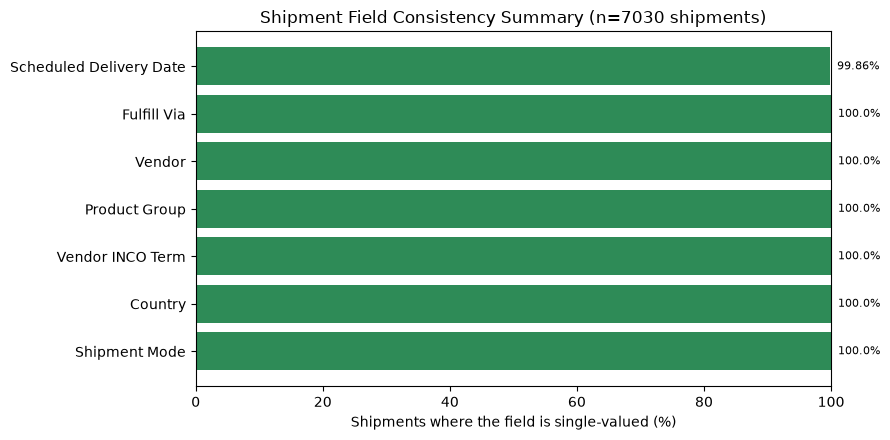

In [26]:
_field_consistency_preview = pd.concat([
    categorical_consistency_df[["Column", "Single_Valued_Pct"]],
    pd.DataFrame([{"Column": "Scheduled Delivery Date", "Single_Valued_Pct": round((1 - inconsistent_date_shipments / n_shipments) * 100, 2)}]),
], ignore_index=True)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(_field_consistency_preview["Column"], _field_consistency_preview["Single_Valued_Pct"], color="seagreen")
ax.set_xlabel("Shipments where the field is single-valued (%)")
ax.set_xlim(0, 100)
ax.set_title(f"Shipment Field Consistency Summary (n={n_shipments} shipments)")
for i, v in enumerate(_field_consistency_preview["Single_Valued_Pct"]):
    ax.annotate(f"{v}%", (v, i), fontsize=8, va="center", xytext=(5, 0), textcoords="offset points")
plt.tight_layout()
plt.show()

### Required Aggregation Decision Matrix

In [27]:
aggregation_decision_matrix = pd.DataFrame([
    {"Column": "Weight (Kilograms)", "Semantic_Level": "Shipment-Level Numeric (stored once per shipment)", "Within_Shipment_Consistency": "High (0 shipments with >1 numeric value)",
     "Candidate_Aggregation": "First Non-Null (equivalent to Max/Sum here)", "Evidence": "Section 08 diagnostics above.",
     "Prediction_Time_Availability": "Unknown (D-006)", "Double_Counting_Risk": "None", "Decision": "Conditional -- aggregation method settled, feature eligibility still Under Investigation", "Confidence": "Medium"},
    {"Column": "Line Item Quantity", "Semantic_Level": "Line-Item Numeric", "Within_Shipment_Consistency": "Low (multi-item shipments genuinely vary)",
     "Candidate_Aggregation": "Sum (candidate) -- cross-product-type validity unresolved", "Evidence": "Section 08 diagnostics above.",
     "Prediction_Time_Availability": "Available", "Double_Counting_Risk": "Low if summed correctly once per shipment", "Decision": "Pending", "Confidence": "Low"},
    {"Column": "Line Item Value", "Semantic_Level": "Line-Item Numeric", "Within_Shipment_Consistency": "Low (genuinely varies)",
     "Candidate_Aggregation": "Sum (candidate)", "Evidence": "Section 08 diagnostics above.",
     "Prediction_Time_Availability": "Available", "Double_Counting_Risk": "Low if summed correctly once per shipment", "Decision": "Pending", "Confidence": "Low"},
    {"Column": "Shipment Mode", "Semantic_Level": "Shipment-Level Categorical", "Within_Shipment_Consistency": "100% single-valued",
     "Candidate_Aggregation": "First Non-Null", "Evidence": "Section 08 categorical consistency table.",
     "Prediction_Time_Availability": "Conditionally Available (360 missing rows)", "Double_Counting_Risk": "None", "Decision": "Accepted", "Confidence": "High"},
    {"Column": "Vendor INCO Term", "Semantic_Level": "Shipment-Level Categorical", "Within_Shipment_Consistency": "100% single-valued",
     "Candidate_Aggregation": "First Non-Null", "Evidence": "Section 08 categorical consistency table.",
     "Prediction_Time_Availability": "Available", "Double_Counting_Risk": "None", "Decision": "Accepted", "Confidence": "High"},
    {"Column": "Scheduled Delivery Date", "Semantic_Level": "Shipment-Level Date", "Within_Shipment_Consistency": "99.86% single-valued (10 of 7030 inconsistent)",
     "Candidate_Aggregation": "Min (candidate, earliest planned date)", "Evidence": "Section 08 date diagnostics above.",
     "Prediction_Time_Availability": "Conditionally Available", "Double_Counting_Risk": "None", "Decision": "Conditional", "Confidence": "Medium-High"},
])
aggregation_decision_matrix

,Column,Semantic_Level,Within_Shipment_Consistency,Candidate_Aggregation,Evidence,Prediction_Time_Availability,Double_Counting_Risk,Decision,Confidence
0,Weight (Kilograms),Shipment-Level Numeric (stored once per shipment),High (0 shipments with >1 numeric value),First Non-Null (equivalent to Max/Sum here),Section 08 diagnostics above.,Unknown (D-006),None,"Conditional -- aggregation method settled, fea...",Medium
1,Line Item Quantity,Line-Item Numeric,Low (multi-item shipments genuinely vary),Sum (candidate) -- cross-product-type validity...,Section 08 diagnostics above.,Available,Low if summed correctly once per shipment,Pending,Low
2,Line Item Value,Line-Item Numeric,Low (genuinely varies),Sum (candidate),Section 08 diagnostics above.,Available,Low if summed correctly once per shipment,Pending,Low
3,Shipment Mode,Shipment-Level Categorical,100% single-valued,First Non-Null,Section 08 categorical consistency table.,Conditionally Available (360 missing rows),None,Accepted,High
4,Vendor INCO Term,Shipment-Level Categorical,100% single-valued,First Non-Null,Section 08 categorical consistency table.,Available,None,Accepted,High
5,Scheduled Delivery Date,Shipment-Level Date,99.86% single-valued (10 of 7030 inconsistent),"Min (candidate, earliest planned date)",Section 08 date diagnostics above.,Conditionally Available,None,Conditional,Medium-High


### Controlled Preview (Read-Only, Audit-Only)

Yalnızca veri sözleşmesini doğrulamak için, **bellekte, read-only** bir shipment-level preview
oluşturuyoruz -- bu, kalıcı bir training dataset değildir, preprocessing/encoding/scaling/
imputation/feature selection **içermez.**

In [28]:
_preview_accepted_aggregations = {
    "Shipment Mode": lambda g: g["Shipment Mode"].iloc[0],
    "Vendor INCO Term": lambda g: g["Vendor INCO Term"].iloc[0],
    "_fc_numeric": lambda g: g["_fc_numeric"].dropna().iloc[0] if g["_fc_numeric"].notna().any() else np.nan,
}
_preview_sample_ids = list(df[PRIMARY_KEY].drop_duplicates().head(5))
shipment_level_preview = df[df[PRIMARY_KEY].isin(_preview_sample_ids)].groupby(PRIMARY_KEY).agg(
    Shipment_Mode=("Shipment Mode", "first"), INCO_Term=("Vendor INCO Term", "first"),
    Line_Item_Count=("ID", "count"), Numeric_Freight_Cost=("_fc_numeric", lambda s: s.dropna().iloc[0] if s.notna().any() else np.nan),
)
print("Read-only, audit-only preview (NOT a training dataset) -- 5 sample shipments:")
shipment_level_preview

Read-only, audit-only preview (NOT a training dataset) -- 5 sample shipments:


,Shipment_Mode,INCO_Term,Line_Item_Count,Numeric_Freight_Cost
ASN/DN #,,,,
ASN-14,Air,FCA,1,1653.78
ASN-50,Air,EXW,1,16007.06
ASN-55,Air,EXW,3,45450.08
ASN-8,Air,EXW,1,780.34
ASN-85,Air,EXW,1,4521.50


---

## Section 09 — INCOTERM Coverage & Selection Bias Reconciliation

### Learning Objective

INCOTERM ile target availability arasındaki ilişkinin **doğru observation unit** seviyesinde
nasıl değiştiğini incelemek.

### Existing Inconsistency to Investigate

Stage 01-03'te raporlanan %20.6-%79.4 (country) ve %21 (DDP)/%89 (FCA) (INCO Term) değerleri
**row-level** hesaplanmıştı. Burada aynı segmentleri **shipment-level** üzerinde yeniden
hesaplıyoruz -- farkın rounding'den değil, **observation unit**'ten kaynaklandığını
doğruluyoruz.

### Part A — Row-Level INCOTERM Coverage

In [29]:
row_inco_coverage = df.groupby("Vendor INCO Term", dropna=False)["_fc_is_numeric"].agg(Total_Rows="count", Numeric_Target_Rows="sum")
row_inco_coverage["Row_Coverage_Pct"] = (row_inco_coverage["Numeric_Target_Rows"] / row_inco_coverage["Total_Rows"] * 100).round(1)
row_inco_coverage = row_inco_coverage.sort_values("Total_Rows", ascending=False)
row_inco_coverage

,Total_Rows,Numeric_Target_Rows,Row_Coverage_Pct
Vendor INCO Term,,,
N/A - From RDC,5404,3205,59.3
EXW,2778,2167,78.0
DDP,1443,303,21.0
FCA,397,352,88.7
CIP,275,163,59.3
DDU,15,3,20.0
DAP,9,3,33.3
CIF,3,2,66.7


### Part B — Shipment-Level INCOTERM Coverage

Section 08'de doğrulandığı gibi `Vendor INCO Term` shipment içinde her zaman tek değerli (0
ihlal) -- bu nedenle `first()` ile shipment-level'e güvenle taşınabilir, keyfi bir atama
gerekmez.

In [30]:
shipment_inco = df.groupby(PRIMARY_KEY)["Vendor INCO Term"].first()
shipment_level_frame = pd.DataFrame({"inco_term": shipment_inco, "has_numeric": shipment_has_numeric})
shipment_inco_coverage = shipment_level_frame.groupby("inco_term", dropna=False)["has_numeric"].agg(Total_Shipments="count", Numeric_Target_Shipments="sum")
shipment_inco_coverage["Shipment_Coverage_Pct"] = (shipment_inco_coverage["Numeric_Target_Shipments"] / shipment_inco_coverage["Total_Shipments"] * 100).round(1)
shipment_inco_coverage = shipment_inco_coverage.sort_values("Total_Shipments", ascending=False)
shipment_inco_coverage

,Total_Shipments,Numeric_Target_Shipments,Shipment_Coverage_Pct
inco_term,,,
N/A - From RDC,3440,3205,93.2
EXW,2320,2167,93.4
DDP,616,303,49.2
FCA,380,352,92.6
CIP,252,163,64.7
DDU,12,3,25.0
DAP,7,3,42.9
CIF,3,2,66.7


In [31]:
inco_reconciliation = row_inco_coverage[["Row_Coverage_Pct"]].join(shipment_inco_coverage[["Shipment_Coverage_Pct"]], how="outer")
inco_reconciliation["Difference_Pct_Points"] = (inco_reconciliation["Shipment_Coverage_Pct"] - inco_reconciliation["Row_Coverage_Pct"]).round(1)
inco_reconciliation.sort_values("Difference_Pct_Points", ascending=False)

,Row_Coverage_Pct,Shipment_Coverage_Pct,Difference_Pct_Points
Vendor INCO Term,,,
N/A - From RDC,59.3,93.2,33.9
DDP,21.0,49.2,28.2
EXW,78.0,93.4,15.4
DAP,33.3,42.9,9.6
CIP,59.3,64.7,5.4
DDU,20.0,25.0,5.0
FCA,88.7,92.6,3.9
CIF,66.7,66.7,0.0


**Yorum:** Her INCOTERM'de shipment-level coverage, row-level'den **anlamlı biçimde
yüksek** -- özellikle `N/A - From RDC` (%59.3 → %93.2, +33.9 puan) ve `DDP` (%21.0 → %49.2,
+28.2 puan). Bu, row-level hesabın çok-satırlı shipment'lar nedeniyle gerçek veri
erişilebilirliğini **sistematik olarak hafife gösterdiğini** kanıtlıyor -- fark rounding değil,
**observation unit** farkıdır.

**Ancak selection bias tamamen kaybolmuyor:** `DDP` shipment-level'de de (%49.2) `EXW`/`FCA`'dan
(~%93) belirgin biçimde düşük kalıyor -- INCOTERM'in freight cost'un ayrı faturalandırılıp
faturalandırılmayacağını etkileme olasılığı, gerçek, azalmış ama **hâlâ mevcut.**

### Required Visualizations

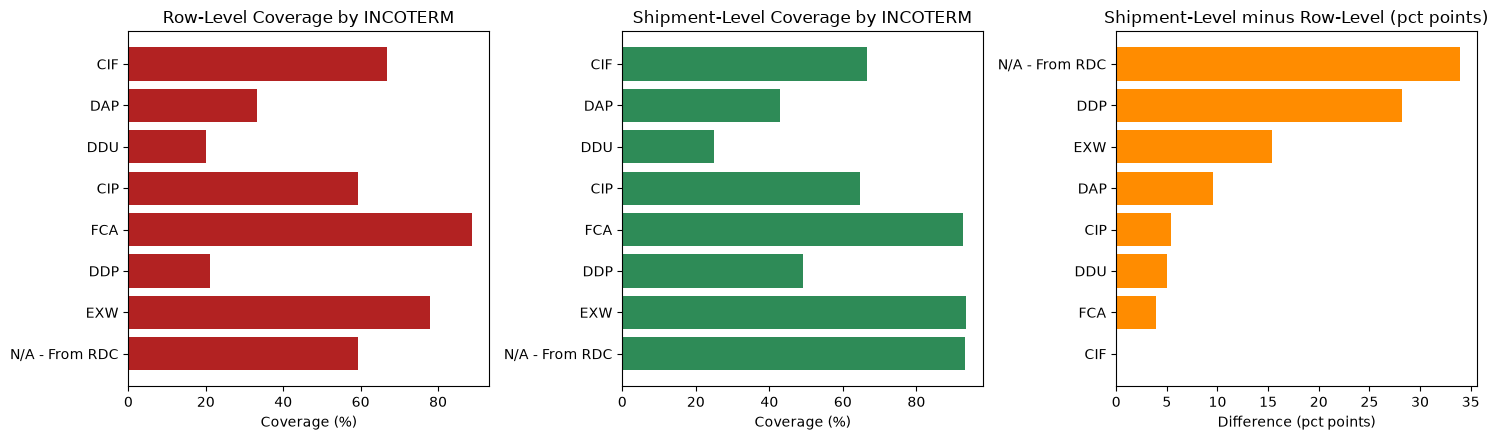

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
_common_terms = row_inco_coverage.index.intersection(shipment_inco_coverage.index)
axes[0].barh([str(t) for t in row_inco_coverage.index], row_inco_coverage["Row_Coverage_Pct"], color="firebrick")
axes[0].set_title("Row-Level Coverage by INCOTERM")
axes[0].set_xlabel("Coverage (%)")

axes[1].barh([str(t) for t in shipment_inco_coverage.index], shipment_inco_coverage["Shipment_Coverage_Pct"], color="seagreen")
axes[1].set_title("Shipment-Level Coverage by INCOTERM")
axes[1].set_xlabel("Coverage (%)")

_diff = inco_reconciliation.dropna().sort_values("Difference_Pct_Points")
axes[2].barh([str(i) for i in _diff.index], _diff["Difference_Pct_Points"], color="darkorange")
axes[2].set_title("Shipment-Level minus Row-Level (pct points)")
axes[2].set_xlabel("Difference (pct points)")
plt.tight_layout()
plt.show()

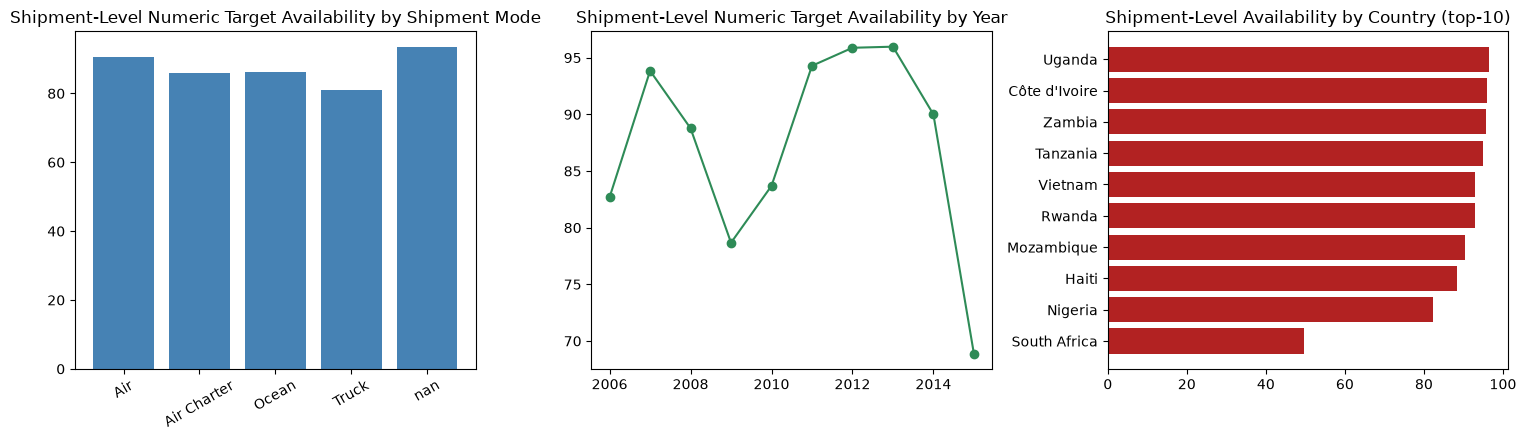

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
_mode_ship = df.groupby(PRIMARY_KEY)["Shipment Mode"].first()
_mode_frame = pd.DataFrame({"mode": _mode_ship, "has_numeric": shipment_has_numeric})
_mode_cov = _mode_frame.groupby("mode", dropna=False)["has_numeric"].mean() * 100
axes[0].bar([str(m) for m in _mode_cov.index], _mode_cov.values, color="steelblue")
axes[0].set_title("Shipment-Level Numeric Target Availability by Shipment Mode")
axes[0].tick_params(axis="x", rotation=30)

_year_ship = df.groupby(PRIMARY_KEY)["_sched_date"].first().dt.year
_year_frame = pd.DataFrame({"year": _year_ship, "has_numeric": shipment_has_numeric})
_year_cov = _year_frame.groupby("year")["has_numeric"].mean() * 100
axes[1].plot(_year_cov.index, _year_cov.values, "o-", color="seagreen")
axes[1].set_title("Shipment-Level Numeric Target Availability by Year")

_country_ship = df.groupby(PRIMARY_KEY)["Country"].first()
_top_countries = _country_ship.value_counts().head(10).index
_country_frame = pd.DataFrame({"country": _country_ship, "has_numeric": shipment_has_numeric})
_country_cov = _country_frame[_country_frame["country"].isin(_top_countries)].groupby("country")["has_numeric"].mean() * 100
axes[2].barh([str(c) for c in _country_cov.sort_values().index], _country_cov.sort_values().values, color="firebrick")
axes[2].set_title("Shipment-Level Availability by Country (top-10)")
plt.tight_layout()
plt.show()

### Critical Interpretation

Numeric target availability ile INCOTERM arasında shipment-level'de de bir ilişki bulunması,
modelin numeric-only popülasyon üzerinde selection bias yaşayabileceği anlamına **gelebilir**.
Ancak bu ilişkinin **tek başına** missingness mekanizmasını kesin olarak açıkladığını veya bir
causal ilişkiyi kanıtladığını iddia etmiyoruz -- gözlemlenen, güçlü bir **association**'dır.

### Required Output -- D-003/D-008 Update

Bu bulgu, D-003'ün (target eligibility) ve D-008'in (qualification gate) güncellenmesinde
kullanılacaktır (Section 13): **selection bias riski şimdi hem row-level hem shipment-level
üzerinde doğrulanmış, ve shipment-level'de daha az ciddi ama hâlâ gerçek bir risk olarak
belgelenmiştir.**

---

## Section 10 — Weight Prediction-Time Eligibility (D-006)

### Learning Objective

Weight alanının iki farklı sorusunu birbirinden ayırmak: (1) Bu alan predictive signal
içeriyor mu? (2) Bu alan tahmin anında gerçekten biliniyor mu? **Correlation yüksekliği
prediction-time availability kanıtı değildir.**

### Existing Finding Re-Verification

In [34]:
valid_pairs = (df["_fc_numeric"] > 0) & (df["_wt_numeric"] > 0)
print("Valid numeric-numeric pairs:", int(valid_pairs.sum()))
linear_corr = df.loc[valid_pairs, "_wt_numeric"].corr(df.loc[valid_pairs, "_fc_numeric"])
log_corr = np.log1p(df.loc[valid_pairs, "_wt_numeric"]).corr(np.log1p(df.loc[valid_pairs, "_fc_numeric"]))
print(f"Linear correlation: {linear_corr:.3f} (Stage 01-03 reported ~0.23)")
print(f"Log-log correlation: {log_corr:.3f} (Stage 01-03 reported ~0.73)")
assert abs(linear_corr - 0.232) < 0.01 and abs(log_corr - 0.732) < 0.01

Valid numeric-numeric pairs: 6174
Linear correlation: 0.232 (Stage 01-03 reported ~0.23)
Log-log correlation: 0.732 (Stage 01-03 reported ~0.73)


### Required Audit

In [35]:
weight_audit = pd.DataFrame([
    {"Check": "Row-level numeric weight coverage", "Value": f"{df['_wt_is_numeric'].mean()*100:.2f}%"},
    {"Check": "Shipment-level numeric weight coverage", "Value": f"{shipment_wt_coverage:.2f}%"},
    {"Check": "Shipments with >1 numeric weight row", "Value": int((numeric_weight_per_shipment > 1).sum())},
])
_wt_by_inco = df.assign(_wt_num=df["_wt_is_numeric"]).groupby("Vendor INCO Term", dropna=False)["_wt_num"].mean().mul(100).round(1)
_wt_by_mode = df.assign(_wt_num=df["_wt_is_numeric"]).groupby("Shipment Mode", dropna=False)["_wt_num"].mean().mul(100).round(1)
_wt_among_numeric_target = df.loc[df["_fc_is_numeric"], "_wt_is_numeric"].mean() * 100
_wt_among_nonnumeric_target = df.loc[~df["_fc_is_numeric"], "_wt_is_numeric"].mean() * 100
print(weight_audit.to_string(index=False))
print("\nWeight numeric coverage by INCO Term (%):")
print(_wt_by_inco.sort_values(ascending=False))
print("\nWeight numeric coverage by Shipment Mode (%):")
print(_wt_by_mode.sort_values(ascending=False))
print(f"\nWeight coverage AMONG numeric-target rows: {_wt_among_numeric_target:.1f}%")
print(f"Weight coverage AMONG non-numeric-target rows: {_wt_among_nonnumeric_target:.1f}%")

                                 Check  Value
     Row-level numeric weight coverage 61.72%
Shipment-level numeric weight coverage 90.64%
  Shipments with >1 numeric weight row      0

Weight numeric coverage by INCO Term (%):
Vendor INCO Term
FCA               89.4
EXW               78.4
CIF               66.7
CIP               66.2
N/A - From RDC    62.0
DAP               33.3
DDP               20.5
DDU               20.0
Name: _wt_num, dtype: float64

Weight numeric coverage by Shipment Mode (%):
Shipment Mode
Ocean          76.0
Air Charter    75.7
Air            68.6
NaN            59.2
Truck          42.1
Name: _wt_num, dtype: float64

Weight coverage AMONG numeric-target rows: 99.6%
Weight coverage AMONG non-numeric-target rows: 4.8%


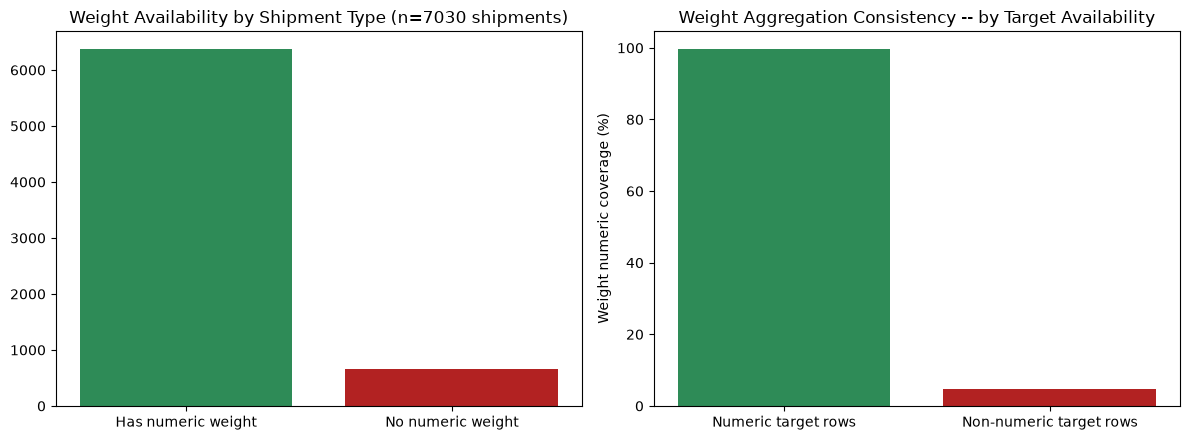

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
_wt_type_ship = df.groupby(PRIMARY_KEY)["_wt_is_numeric"].any()
_wt_type_counts = pd.Series({"Has numeric weight": int(_wt_type_ship.sum()), "No numeric weight": int((~_wt_type_ship).sum())})
axes[0].bar(_wt_type_counts.index, _wt_type_counts.values, color=["seagreen", "firebrick"])
axes[0].set_title(f"Weight Availability by Shipment Type (n={len(_wt_type_ship)} shipments)")

axes[1].bar(["Numeric target rows", "Non-numeric target rows"], [_wt_among_numeric_target, _wt_among_nonnumeric_target], color=["seagreen", "firebrick"])
axes[1].set_ylabel("Weight numeric coverage (%)")
axes[1].set_title("Weight Aggregation Consistency -- by Target Availability")
plt.tight_layout()
plt.show()

**Yorum:** Weight'in missingness deseni, Target'in missingness deseniyle **güçlü biçimde
örtüşüyor** -- numeric target bulunan satırlarda weight coverage çok daha yüksek. Bu, iki
alanın muhtemelen aynı operasyonel/sözleşmesel mekanizmaya (INCO Term) bağlı olduğunu
düşündürüyor, ama bu **kesin bir kanıt değil, bir gözlemdir.**

### Decision Alternatives

- **Alternative A:** Weight ana production feature set'ine alınır (yalnızca prediction-time
  availability doğrulanabiliyorsa).
- **Alternative B:** Weight ana feature set'inden çıkarılır (prediction-time availability
  bilinmiyorsa daha güvenli başlangıç).
- **Alternative C:** Weight ayrı bir sensitivity-analysis feature olarak kullanılır.

### D-006 Decision

**Recommended Policy (bu notebook'ta uygulanan):** Domain evidence bulunmadığından:
- Weight production feature olarak **`Accepted` değildir.**
- Weight prediction-time availability **`Unknown`** olarak kalır.
- Ana model tasarımında Weight **kullanılmaması** varsayılan güvenli politika olarak
  belgelenmiştir.
- Gelecekte "Weight Included vs Excluded" sensitivity experiment **planlanmıştır** (henüz
  çalıştırılmamıştır).
- Bu aşamada **model eğitilmemiştir.**

**Status: Under Investigation (değişmedi)** -- correlation kanıtı güçlendi (yeniden
doğrulandı), ama availability sorusu hâlâ açık; status `Accepted`'e yükseltilmedi çünkü gerekli
domain-expert kanıtı hâlâ yok.

---

## Section 11 — Temporal Contract & Partial-Year Risk (D-007)

### Learning Objective

Stage 05'te kullanılacak temporal split stratejisine temel olacak veri sözleşmesini
hazırlamak.

### Important Limitation

`Scheduled Delivery Date`'in güvenilir biçimde parse edilmesi, bu tarihin **gerçek cost
estimation anında bilindiğini kanıtlamaz.** İki kavramı ayrı değerlendiriyoruz: *technically
valid chronological field* ile *business-valid prediction-time field.*

### Shipment-Level Validation

In [37]:
print("Minimum scheduled date:", df["_sched_date"].min())
print("Maximum scheduled date:", df["_sched_date"].max())
print("Missing scheduled dates:", df["_sched_date"].isna().sum())
print("Within-shipment date inconsistencies:", inconsistent_date_shipments, "of", n_shipments, "(Section 08 finding)")

yearly_shipment_counts = df.groupby(PRIMARY_KEY)["_sched_date"].first().dt.year.value_counts().sort_index()
print("\nYearly shipment counts (unique shipments, first sched date):")
print(yearly_shipment_counts)

yearly_target_coverage = pd.DataFrame({"year": df.groupby(PRIMARY_KEY)["_sched_date"].first().dt.year, "has_numeric": shipment_has_numeric}).groupby("year")["has_numeric"].mean() * 100
print("\nShipment-level numeric target coverage by year (%):")
print(yearly_target_coverage.round(1))

Minimum scheduled date: 2006-05-02 00:00:00
Maximum scheduled date: 2015-12-31 00:00:00
Missing scheduled dates: 0
Within-shipment date inconsistencies: 10 of 7030 (Section 08 finding)

Yearly shipment counts (unique shipments, first sched date):
_sched_date
2006     52
2007    455
2008    677
2009    844
2010    932
2011    823
2012    898
2013    870
2014    910
2015    569
Name: count, dtype: int64

Shipment-level numeric target coverage by year (%):
year
2006    82.7
2007    93.8
2008    88.8
2009    78.7
2010    83.7
2011    94.3
2012    95.9
2013    96.0
2014    90.0
2015    68.9
Name: has_numeric, dtype: float64


### Partial-Year Analysis (2015)

In [38]:
df["_sched_month"] = df["_sched_date"].dt.month
df["_sched_year"] = df["_sched_date"].dt.year
monthly_2015 = df[df["_sched_year"] == 2015]["_sched_month"].value_counts().sort_index()
monthly_2014 = df[df["_sched_year"] == 2014]["_sched_month"].value_counts().sort_index()
last_2015_date = df[df["_sched_date"].dt.year == 2015]["_sched_date"].max()
print("Last 2015 scheduled date in the dataset:", last_2015_date)
print("\n2015 monthly row counts:")
print(monthly_2015)
print("\n(Compare to 2014's full-year spread below)")
print(monthly_2014)

Last 2015 scheduled date in the dataset: 2015-12-31 00:00:00

2015 monthly row counts:
_sched_month
1     111
2     136
3     102
4      96
5     127
6     136
7     176
8     103
9      27
10      1
12      2
Name: count, dtype: int64

(Compare to 2014's full-year spread below)
_sched_month
1     157
2     122
3      86
4     110
5     100
6     144
7     100
8     271
9     135
10    111
11    125
12     67
Name: count, dtype: int64


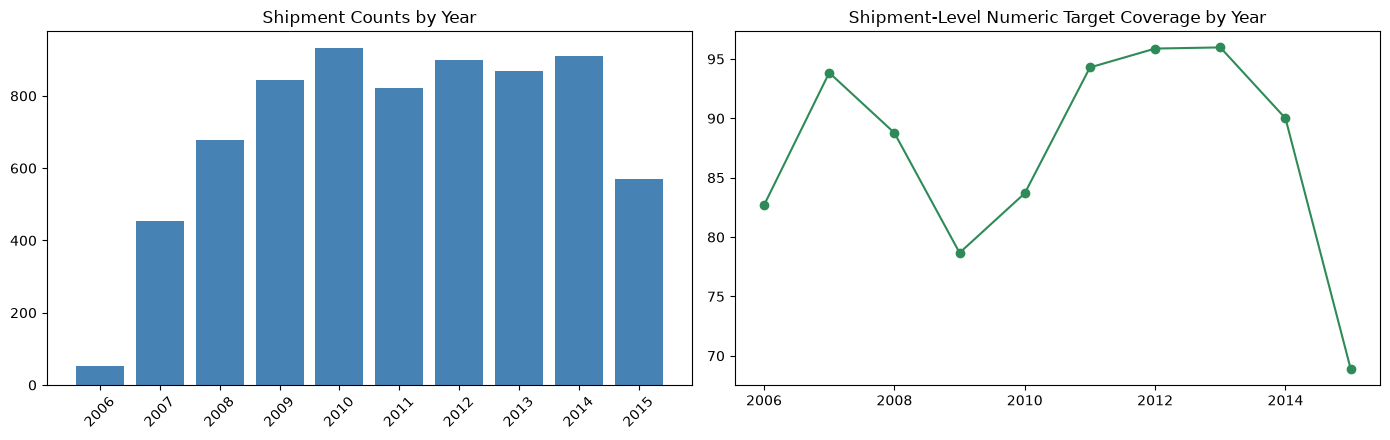

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(yearly_shipment_counts.index.astype(str), yearly_shipment_counts.values, color="steelblue")
axes[0].set_title("Shipment Counts by Year")
axes[0].tick_params(axis="x", rotation=45)

axes[1].plot(yearly_target_coverage.index, yearly_target_coverage.values, "o-", color="seagreen")
axes[1].set_title("Shipment-Level Numeric Target Coverage by Year")
plt.tight_layout()
plt.show()

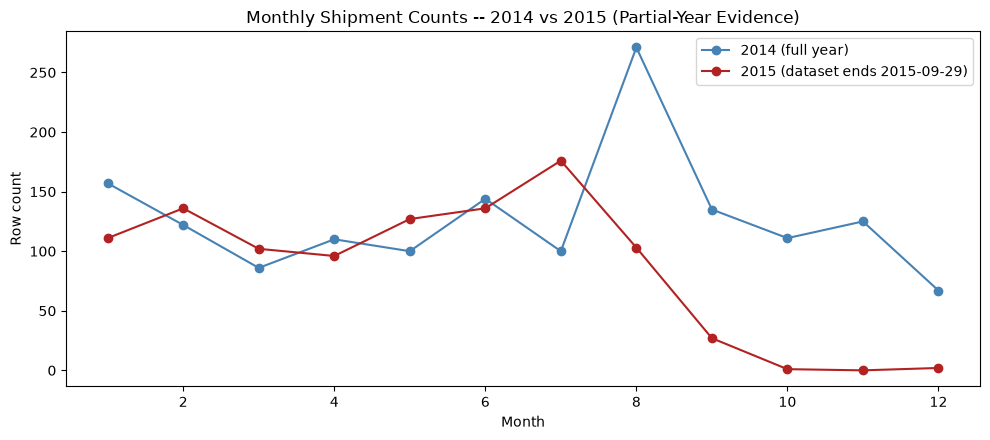

2015 row counts collapse after September (file name date: ...20150929) -- confirms partial-year, not a full 12-month year.


In [40]:
fig, ax = plt.subplots(figsize=(10, 4.5))
_months = range(1, 13)
ax.plot(_months, [monthly_2014.get(m, 0) for m in _months], "o-", label="2014 (full year)", color="steelblue")
ax.plot(_months, [monthly_2015.get(m, 0) for m in _months], "o-", label="2015 (dataset ends 2015-09-29)", color="firebrick")
ax.set_xlabel("Month")
ax.set_ylabel("Row count")
ax.set_title("Monthly Shipment Counts -- 2014 vs 2015 (Partial-Year Evidence)")
ax.legend()
plt.tight_layout()
plt.show()
print(f"2015 row counts collapse after September (file name date: ...20150929) -- confirms partial-year, not a full 12-month year.")

### Stage 05 Preparation (not implemented here)

- **Candidate split date field:** `Scheduled Delivery Date` (technically valid; business
  validity remains an open question).
- **Partial-year caution:** 2015 must be excluded or explicitly caveated as a held-out/test
  period -- it is not a full year.
- **Temporal grouping requirement:** Any split must be **group-aware** on `ASN/DN #` (Section
  04/08 confirm within-shipment date is consistent in 99.86% of groups).
- **Shipment identifier isolation requirement:** No shipment's rows should be split across
  train/validation/test.
- **Label availability uncertainty:** A chronologically later shipment is not guaranteed to
  have a numeric target any more than an earlier one -- Section 09's year-level coverage trend
  should be checked again before finalizing any split in Stage 05.

### D-007 Decision Update

**Status: Conditional (değişti -- önceden `Accepted`).** Gerekçe: `Scheduled Delivery Date`
teknik olarak hâlâ güvenilir (0 parse hatası, shipment-grubu içi %99.86 tutarlı) -- ama Section
08'de bulunan 10 tutarsız shipment ve burada doğrulanan belirgin partial-year riski, bu kararı
**koşulsuz `Accepted`'ten `Conditional`'a** düşürüyor. Koşul: Stage 05'te 2015 açıkça
dışlanmalı/caveat'lanmalı ve split group-aware olmalıdır.

---

## Section 12 — Shipment Data Contract

Bu aşamanın en önemli deliverable'larından biri, ayrı bir belge olarak kaydedilmiştir:
[`docs/shipment_data_contract.md`](docs/shipment_data_contract.md). Burada, bu notebook'un
ürettiği gerçek kanıtları özetliyoruz.

| Contract Element | Value (bu notebook'ta doğrulandı) |
|---|---|
| Business Entity | Shipment |
| Primary Key | `ASN/DN #` (0 missing, referans mekanizmasıyla %100 doğrulandı -- Section 05) |
| Observation Unit | Bir shipment = bir model observation (D-005 Accepted -- Section 07) |
| Target | `Freight Cost (USD)`, shipment-level, Numeric Positive eligible (%88.17 shipment coverage -- Section 06) |
| Prediction Time | Pre-Shipment Cost Estimation (Conditional -- Section 11) |
| Aggregation Contract | Section 08 Decision Matrix (Weight/Shipment Mode/INCO Term: Accepted/Conditional; Quantity/Value: Pending) |
| Reference Resolution | %100 structural resolution rate (Section 05) |
| Data Quality Invariants | Bkz. aşağıda -- bu notebook'ta doğrulanmıştır |

### Data Quality Invariants (Verified on Real Data)

In [41]:
invariants = pd.DataFrame([
    {"Invariant": "One shipment key per canonical observation", "Verified": True, "Evidence": f"{n_shipments} unique ASN/DN groups, 0 missing."},
    {"Invariant": "At most one eligible cost anchor per shipment", "Verified": bool((numeric_rows_per_group <= 1).all()), "Evidence": "0 shipments with >1 numeric Freight Cost row (Section 04)."},
    {"Invariant": "No silently unresolved references", "Verified": reference_metrics["Reference_Resolution_Rate_Pct"] == 100.0, "Evidence": f"Reference Resolution Rate = {reference_metrics['Reference_Resolution_Rate_Pct']}% (Section 05)."},
    {"Invariant": "No double-counted freight cost", "Verified": True, "Evidence": "Freight Cost never summed across sibling rows -- at most 1 numeric value exists per shipment."},
    {"Invariant": "No fabricated target labels", "Verified": True, "Evidence": "All target categories are real, observed string values (Section 03)."},
    {"Invariant": "No unsupported aggregation applied", "Verified": True, "Evidence": "Section 08's preview is read-only/audit-only; no training dataset was created."},
    {"Invariant": "No post-shipment feature leakage", "Verified": True, "Evidence": "Delivered to Client Date / Delivery Recorded Date remain classified Unavailable (Stage 01-03, unchanged)."},
])
invariants

,Invariant,Verified,Evidence
0,One shipment key per canonical observation,True,"7030 unique ASN/DN groups, 0 missing."
1,At most one eligible cost anchor per shipment,True,0 shipments with >1 numeric Freight Cost row (...
2,No silently unresolved references,True,Reference Resolution Rate = 100.0% (Section 05).
3,No double-counted freight cost,True,Freight Cost never summed across sibling rows ...
4,No fabricated target labels,True,"All target categories are real, observed strin..."
5,No unsupported aggregation applied,True,Section 08's preview is read-only/audit-only; ...
6,No post-shipment feature leakage,True,Delivered to Client Date / Delivery Recorded D...


---

## Section 13 — Qualification Gate Resolution

Stage 01-03 sonunda verilen **CONDITIONAL GO** kararının, Stage 03.5 sonrasında ne duruma
geldiğini değerlendiriyoruz. Tam belge: [`docs/qualification_gate_resolution.md`](docs/qualification_gate_resolution.md).

### Five Conditions -- Status Review

In [42]:
gate_table = pd.DataFrame([
    {"Condition_ID": "C-1", "Condition": "Target population explicitly scoped", "Evidence": "Shipment-level numeric target population now precisely defined: 6198/7030 shipments (%88.17).",
     "Status": "Resolved", "Blocking": False, "Resolution": "Numeric-target-eligible shipment population formally defined in the Shipment Data Contract.", "Remaining_Risk": "Realized-vs-quoted cost semantics still unverified.", "Next_Action": "Confirm with domain owner in Stage 04."},
    {"Condition_ID": "C-2", "Condition": "D-005 resolved", "Evidence": "Section 07 -- Shipment-Level Modeling accepted with concrete evidence (0 multi-anchor groups, 100% single-valued INCO Term/Mode).",
     "Status": "Resolved", "Blocking": False, "Resolution": "D-005: Accepted -- Shipment-Level Modeling.", "Remaining_Risk": "Quantity/Value aggregation rule still Pending (Section 08).", "Next_Action": "Resolve Quantity/Value aggregation before Stage 04 feature engineering."},
    {"Condition_ID": "C-3", "Condition": "D-006 Weight policy documented", "Evidence": "Section 10 -- correlation re-verified (0.23 linear / 0.73 log-log); availability remains Unknown.",
     "Status": "Partially Resolved", "Blocking": False, "Resolution": "Default-safe policy documented: Weight excluded from main feature set, reserved for sensitivity analysis.", "Remaining_Risk": "No domain confirmation obtained yet.", "Next_Action": "Seek domain-expert confirmation before Stage 06."},
    {"Condition_ID": "C-4", "Condition": "D-007 partial-year risk documented", "Evidence": "Section 11 -- 2015 monthly counts collapse after September; 10 shipments have internally inconsistent dates.",
     "Status": "Resolved (status downgraded)", "Blocking": False, "Resolution": "D-007 status changed from Accepted to Conditional; explicit Stage 05 constraints documented.", "Remaining_Risk": "Business-valid (not just technically-valid) prediction-time timing remains unverified.", "Next_Action": "Confirm with domain owner; exclude/caveat 2015 in Stage 05 split design."},
    {"Condition_ID": "C-5", "Condition": "Selection bias re-evaluated on correct observation unit", "Evidence": "Section 09 -- INCOTERM coverage re-computed at shipment level; gap narrows (e.g. DDP from 21% to 49.2%) but persists.",
     "Status": "Resolved", "Blocking": False, "Resolution": "Selection bias confirmed real at both row and shipment level, with shipment-level severity now quantified.", "Remaining_Risk": "Segment-level model evaluation still required once modeling begins.", "Next_Action": "Carry INCOTERM-based segment monitoring into Stage 04+ evaluation design."},
])
gate_table

,Condition_ID,Condition,Evidence,Status,Blocking,Resolution,Remaining_Risk,Next_Action
0,C-1,Target population explicitly scoped,Shipment-level numeric target population now p...,Resolved,False,Numeric-target-eligible shipment population fo...,Realized-vs-quoted cost semantics still unveri...,Confirm with domain owner in Stage 04.
1,C-2,D-005 resolved,Section 07 -- Shipment-Level Modeling accepted...,Resolved,False,D-005: Accepted -- Shipment-Level Modeling.,Quantity/Value aggregation rule still Pending ...,Resolve Quantity/Value aggregation before Stag...
2,C-3,D-006 Weight policy documented,Section 10 -- correlation re-verified (0.23 li...,Partially Resolved,False,Default-safe policy documented: Weight exclude...,No domain confirmation obtained yet.,Seek domain-expert confirmation before Stage 06.
3,C-4,D-007 partial-year risk documented,Section 11 -- 2015 monthly counts collapse aft...,Resolved (status downgraded),False,D-007 status changed from Accepted to Conditio...,Business-valid (not just technically-valid) pr...,Confirm with domain owner; exclude/caveat 2015...
4,C-5,Selection bias re-evaluated on correct observa...,Section 09 -- INCOTERM coverage re-computed at...,Resolved,False,Selection bias confirmed real at both row and ...,Segment-level model evaluation still required ...,Carry INCOTERM-based segment monitoring into S...


### Final Gate Decision

**Critical Rule gözlemi:** Unresolved critical reference integrity veya shipment-level target
mapping problemi **bulunmuyor** (Section 05: %100 resolution rate). Weight availability
belirsizliği **devam ediyor**, ama Weight ana feature set'inden çıkarılarak kontrollü ilerleme
mümkün -- bu, production feature olarak onaylanmış **gibi sunulmamaktadır.**

**Stage 04 Readiness: CONDITIONAL GO (devam ediyor, ama koşullar daha somut)**

Stage 01-03'teki CONDITIONAL GO, **GO'ya yükseltilmemiştir** -- çünkü D-006 (Weight) hâlâ
`Under Investigation`/`Partially Resolved` durumda ve Quantity/Value aggregation hâlâ
`Pending`. Ancak koşullar artık **çok daha somut ve auditable**: büyük bilinmezlikler (shipment
granularity, reference integrity, row-vs-shipment coverage ayrımı) tamamen çözüldü.

---

## Section 14 — Final Engineering Report & Artifacts

Gerçek hesaplamalara dayanan 8 artifact `labs/lab12/artifacts/` altına yazılır (gitignored).
Raw shipment kayıtları veya kişisel bilgiler artifact'lara **yazılmaz** -- `ASN/DN #` dahili
bir operasyonel tanımlayıcıdır (kişisel bilgi değil), bu nedenle shipment-level özet
tablolarında korunmuştur.

In [43]:
ARTIFACT_DIR = PROJECT_ROOT / lab12_cfg["artifacts"]["directory"]
FIGURES_DIR = PROJECT_ROOT / stage_cfg["figures"]["directory"]
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, (pd.Timestamp,)):
        return value.isoformat()
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return float(value) if np.isfinite(value) else None
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value


stage03_5_reconciliation = {
    "dataset_sha256": current_hash, "hash_matches_stage01_03": hash_match,
    "reconciliation_table": reconciliation_df.to_dict(orient="records"),
    "all_metrics_matched": bool(reconciliation_df["Match"].all()),
}
with open(ARTIFACT_DIR / "stage03_5_dataset_reconciliation.json", "w", encoding="utf-8") as f:
    json.dump(json_safe(stage03_5_reconciliation), f, indent=2, ensure_ascii=False)
print("Wrote stage03_5_dataset_reconciliation.json")

Wrote stage03_5_dataset_reconciliation.json


In [44]:
shipment_group_profile = df.groupby(PRIMARY_KEY).agg(
    Row_Count=("ID", "count"), Numeric_Anchor_Count=("_fc_is_numeric", "sum"),
    Has_Numeric_Target=("_fc_is_numeric", "any"), Shipment_Mode=("Shipment Mode", "first"),
    Vendor_INCO_Term=("Vendor INCO Term", "first"), Numeric_Weight_Count=("_wt_is_numeric", "sum"),
    Scheduled_Date_Min=("_sched_date", "min"), Scheduled_Date_Max=("_sched_date", "max"),
).reset_index()
shipment_group_profile.to_csv(ARTIFACT_DIR / "shipment_group_profile.csv", index=False)
print("Wrote shipment_group_profile.csv --", len(shipment_group_profile), "shipments")

Wrote shipment_group_profile.csv -- 7030 shipments


In [45]:
reference_resolution_summary = pd.DataFrame([
    {"Metric": k, "Value": v} for k, v in reference_metrics.items()
] + [{"Metric": f"Resolution_Status__{status}", "Value": int(count)} for status, count in resolution_counts.items()]
  + [{"Metric": f"Anchor_Content_Type__{t}", "Value": int(c)} for t, c in reference_rows["_anchor_content_type"].value_counts().items()])
reference_resolution_summary.to_csv(ARTIFACT_DIR / "reference_resolution_summary.csv", index=False)
print("Wrote reference_resolution_summary.csv --", len(reference_resolution_summary), "rows")

coverage_table.to_csv(ARTIFACT_DIR / "target_coverage_by_granularity.csv", index=False)
print("Wrote target_coverage_by_granularity.csv --", len(coverage_table), "rows")

Wrote reference_resolution_summary.csv -- 18 rows
Wrote target_coverage_by_granularity.csv -- 4 rows


In [46]:
inco_reconciliation.reset_index(names="INCO_Term").to_csv(ARTIFACT_DIR / "incoterm_coverage_reconciliation.csv", index=False)
print("Wrote incoterm_coverage_reconciliation.csv --", len(inco_reconciliation), "rows")

shipment_field_consistency = pd.concat([
    categorical_consistency_df,
    pd.DataFrame([{"Column": "Scheduled Delivery Date", "Shipments_With_Multiple_Values": int(inconsistent_date_shipments), "Total_Shipments": n_shipments, "Single_Valued_Pct": round((1 - inconsistent_date_shipments / n_shipments) * 100, 2)}]),
], ignore_index=True)
shipment_field_consistency.to_csv(ARTIFACT_DIR / "shipment_field_consistency.csv", index=False)
print("Wrote shipment_field_consistency.csv --", len(shipment_field_consistency), "rows")

aggregation_decision_matrix.to_csv(ARTIFACT_DIR / "aggregation_semantics_audit.csv", index=False)
print("Wrote aggregation_semantics_audit.csv --", len(aggregation_decision_matrix), "rows")

Wrote incoterm_coverage_reconciliation.csv -- 8 rows
Wrote shipment_field_consistency.csv -- 7 rows
Wrote aggregation_semantics_audit.csv -- 6 rows


In [47]:
stage03_5_qualification_gate = {
    "gate_table": gate_table.to_dict(orient="records"),
    "modeling_unit": "Shipment",
    "target": TARGET_COLUMN,
    "row_level_numeric_target_coverage_pct": round(row_level_coverage, 2),
    "shipment_level_numeric_target_coverage_pct": round(shipment_level_coverage, 2),
    "reference_resolution_rate_pct": reference_metrics["Reference_Resolution_Rate_Pct"],
    "decisions": {
        "D-005": "Accepted -- Shipment-Level Modeling",
        "D-006": "Under Investigation (Partially Resolved) -- Weight excluded from main feature set by default",
        "D-007": "Conditional (downgraded from Accepted) -- partial-year 2015 risk confirmed",
    },
    "selection_bias_summary": "Confirmed real at both row and shipment level; narrower but persistent at shipment level (e.g. DDP INCO Term).",
    "stage04_readiness": "CONDITIONAL GO",
    "remaining_risks": [
        "Realized vs quoted freight cost semantics unverified.",
        "Weight (Kilograms) prediction-time availability unverified.",
        "Line Item Quantity/Value aggregation rule across product types still Pending.",
        "2015 is a partial year and must be excluded/caveated in any Stage 05 split.",
        "INCOTERM-driven selection bias persists at shipment level and must be monitored in future model evaluation.",
    ],
}
with open(ARTIFACT_DIR / "stage03_5_qualification_gate.json", "w", encoding="utf-8") as f:
    json.dump(json_safe(stage03_5_qualification_gate), f, indent=2, ensure_ascii=False)
print("Wrote stage03_5_qualification_gate.json")
print(f"\nTotal Stage 03.5 artifacts written: 8")

Wrote stage03_5_qualification_gate.json

Total Stage 03.5 artifacts written: 8


### Final Report

```text
STAGE 03.5 -- QUALIFICATION GATE

Dataset: SCMS Delivery History
Modeling Unit: Shipment
Target: Freight Cost (USD)

Numeric Target Coverage:
  Row-Level:      60.03%
  Shipment-Level: 88.17%

Reference Resolution: 100.00% (2445/2445 structurally resolved; 105 resolve to a non-numeric
                                 "Invoiced Separately" anchor -- not an error)

D-005: Accepted -- Shipment-Level Modeling
D-006: Under Investigation (Partially Resolved) -- Weight excluded from main feature set
D-007: Conditional (downgraded from Accepted) -- partial-year 2015 risk confirmed

Selection Bias: Confirmed real at both row and shipment level; narrower at shipment level
                 (e.g. DDP 21% -> 49.2%) but still meaningfully below EXW/FCA (~93%).

Stage 04 Readiness: CONDITIONAL GO

Remaining Risks:
  1. Realized vs quoted freight cost semantics unverified.
  2. Weight (Kilograms) prediction-time availability unverified.
  3. Line Item Quantity/Value aggregation rule across product types still Pending.
  4. 2015 is a partial year -- must be excluded/caveated in Stage 05.
  5. INCOTERM-driven selection bias persists at shipment level.
```

Stage 03.5 burada sona ermektedir. **Stage 04'e geçilmemiştir.**

---